In [1]:
from pathlib import Path

import geopandas as gpd
import networkx as nx
import numpy as np
import pandas as pd

# ------------------------------------------------------------------
# Configuration: choose any city listed by AVAILABLE_CITIES below.
# Use the filename slug, for example: medellin, bogota, santa_marta.
# ------------------------------------------------------------------
CITY = "villavicencio"

# Work whether Jupyter starts in the repository root or this notebook's folder.
cwd = Path.cwd().resolve()
repo_root = next(
    path for path in (cwd, cwd / "pedestrian_accessibility", *cwd.parents)
    if (path / "data/input/shape").is_dir()
)

shape_dir = repo_root / "data/input/shape"
table_dir = repo_root / "data/input/table"

AVAILABLE_CITIES = sorted(
    path.stem.removesuffix("_edges").rsplit("-", 1)[0]
    for path in (shape_dir / "edges").glob("*-*_edges.shp")
)
if CITY not in AVAILABLE_CITIES:
    raise ValueError(
        f"Unknown CITY={CITY!r}. Choose one of: {', '.join(AVAILABLE_CITIES)}"
    )

city_name = CITY.replace("_", " " ).title()
output_dir = (
    repo_root
    / "level_sets_blocks"
    / "results"
    / "experiment_1_complete_cities"
    / "persitent_parks_raw"
    / CITY
)
output_dir.mkdir(parents=True, exist_ok=True)

print(f"Selected city: {city_name} ({CITY})")
print(f"Available cities ({len(AVAILABLE_CITIES)}): {', '.join(AVAILABLE_CITIES)}")
print(f"Outputs: {output_dir}")

Selected city: Villavicencio (villavicencio)
Available cities (79): aguachica, apartado, arauca, arjona, armenia, barrancabermeja, barranquilla, bogota, bucaramanga, buga, calarca, caldas, cali, cartagena, cartago, caucasia, cerete, chia, chigorodo, chiquinquira, cienaga, cucuta, duitama, el_carmen_de_bolivar, facatativa, florencia, fundacion, fusagasuga, garzon, granada, ibague, ipiales, jamundi, la_dorada, lorica, magangue, maicao, manizales, manuela, medellin, montelibano, monteria, morroa, neiva, ocana, orito, palmira, pamplona, pasto, pereira, piedecuesta, pitalito, planeta_rica, playa_blanca, popayan, puerto_asis, puerto_boyaca, quibdo, riohacha, rionegro, sabanalarga, sahagun, san_andres, san_jose_del_guaviare, san_vicente_del_caguan, santa_marta, santa_rosa_de_cabal, santander_de_quilichao, saravena, sincelejo, tierralta, tulua, tunja, turbaco, valledupar, villa_del_rosario, villavicencio, yopal, zipaquira
Outputs: /Users/gregorioperez/Documents/Maestria/Investigacion/urban_for

In [2]:
edge_matches = list((shape_dir / "edges").glob(f"{CITY}-*_edges.shp"))
if len(edge_matches) != 1:
    raise ValueError(f"Expected one edge dataset for {CITY!r}; found {edge_matches}")

edge_path = edge_matches[0]
network_id = edge_path.stem.removesuffix("_edges").rsplit("-", 1)[1]
node_path = shape_dir / "nodes" / f"{CITY}-{network_id}_nodes.shp"
if not node_path.exists():
    raise FileNotFoundError(f"Matching node dataset not found: {node_path}")

# Estimate the local UTM zone instead of assuming one city's CRS.
raw_nodes = gpd.read_file(node_path)
metric_crs = raw_nodes.to_crs("EPSG:4326").estimate_utm_crs()
if metric_crs is None:
    raise ValueError(f"Could not estimate a metric CRS for {city_name}.")

road_edges = gpd.read_file(edge_path).to_crs(metric_crs)
road_nodes = raw_nodes.to_crs(metric_crs)
print(f"Network: {edge_path.name}; analysis CRS: {metric_crs.to_string()}")

# Normalize graph identifiers before constructing a NetworkX graph.
road_edges["from"] = road_edges["from"].astype(str)
road_edges["to"] = road_edges["to"].astype(str)
road_nodes["osmid"] = road_nodes["osmid"].astype(str)

# Exact Naismith–Langmuir adjustment used in code/01_Graph_data.ipynb,
# loaded from the project's source slope–velocity table.
speed_table = pd.read_csv(
    table_dir / "slope_velocity_data.csv",
    sep=";",
)
road_edges["speed"] = 0.0

for interval in speed_table.itertuples(index=False):
    in_interval = (
        (road_edges["grade_abs"] > interval.s1)
        & (road_edges["grade_abs"] <= interval.s2)
    )
    road_edges.loc[in_interval, "speed"] = interval.speed

road_edges.loc[road_edges["grade_abs"] == 0, "speed"] = 5.0
road_edges.loc[
    road_edges["grade_abs"] > speed_table["s2"].max(),
    "speed",
] = speed_table.iloc[0]["speed"]
road_edges["impedance_min"] = (
    road_edges["length"]
    / (road_edges["speed"] * 1_000 / 60)
)
# `weight` is the name expected by the original SAWI OD implementation.
road_edges["weight"] = road_edges["impedance_min"]

if not np.isfinite(road_edges["impedance_min"]).all():
    raise ValueError("The pedestrian network contains invalid walking times.")

road_edges[[
    "from", "to", "length", "grade_abs",
    "speed", "impedance_min", "geometry",
]].head()

Network: villavicencio-646_edges.shp; analysis CRS: EPSG:32618


,from,to,length,grade_abs,speed,impedance_min,geometry
0,820875913,7626975359,6.157970,0.022390,3.529412,0.104685,"LINESTRING (654810.195 454974.708, 654811.471 ..."
1,820875913,820876652,6.685635,0.018148,3.529412,0.113656,"LINESTRING (654810.195 454974.708, 654813.613 ..."
2,820875913,820878242,160.562193,0.008827,3.529412,2.729557,"LINESTRING (654649.467 454974.571, 654810.195 ..."
3,820875913,9255576963,8.900964,0.010313,3.529412,0.151316,"LINESTRING (654807.349 454983.095, 654810.195 ..."
4,820875937,7629890939,27.823331,0.019636,3.529412,0.472997,"LINESTRING (653045.7 455128.605, 653068.908 45..."


In [3]:
perimeter_path = (
    shape_dir
    / "Colombia_urban_perimeters_name_pop"
    / "Colombia_urban_perimeters_name_pop.shp"
)

all_urban_perimeters = gpd.read_file(perimeter_path).to_crs(metric_crs)

# Identify every DANE urban perimeter touched by the regional road network.
perimeter_hits = gpd.sjoin(
    road_edges[["geometry"]],
    all_urban_perimeters[["ID_mpio", "Name", "geometry"]],
    how="inner",
    predicate="intersects",
)

city_urban_units = all_urban_perimeters[
    all_urban_perimeters["ID_mpio"].isin(
        perimeter_hits["ID_mpio"].unique()
    )
].copy()

city_polygon = gpd.GeoDataFrame(
    {
        "city": [CITY],
        "network_id": [network_id],
        "geometry": [city_urban_units.geometry.union_all()],
    },
    crs=metric_crs,
)

if city_urban_units.empty:
    raise ValueError(f"The {city_name} network does not intersect an urban perimeter.")

city_urban_units[["ID_mpio", "Name", "pop"]].drop_duplicates()

,ID_mpio,Name,pop
279,50001,VILLAVICENCIO,419657


In [4]:
# ------------------------------------------------------------------
# Add road coverage for municipalities selected by the original city network.
# The polygon is never expanded from supplemental networks: it remains the
# metro area selected above, minus only municipalities with no usable roads.
# ------------------------------------------------------------------
import sys

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

# Reload the helper so this cell uses edits made without restarting Jupyter.
import importlib
import level_sets_blocks.tools.metro_networks as metro_networks

importlib.reload(metro_networks)
extend_metro_network = metro_networks.extend_metro_network

base_city_urban_units = city_urban_units.copy()
metro_boundary_from_main_network = city_polygon.copy()

(
    road_edges,
    road_nodes,
    city_urban_units,
    city_polygon,
    municipality_network_report,
    FLAT_WALKING_SPEED_KMH,
) = extend_metro_network(
    city=CITY,
    network_id=network_id,
    shape_dir=shape_dir,
    metric_crs=metric_crs,
    base_edges=road_edges,
    base_nodes=road_nodes,
    base_city_urban_units=base_city_urban_units,
    speed_table=speed_table,
)

excluded_city_urban_units = base_city_urban_units[
    ~base_city_urban_units["ID_mpio"].astype(str).isin(
        city_urban_units["ID_mpio"].astype(str)
    )
].copy()

excluded_municipalities = municipality_network_report[
    municipality_network_report["status"].eq("excluded_no_usable_roads")
].copy()

print(
    f"Downloaded-road speed (grade_abs = 0): "
    f"{FLAT_WALKING_SPEED_KMH:g} km/h"
)
print(
    f"Metro municipalities retained: "
    f"{municipality_network_report['status'].ne('excluded_no_usable_roads').sum():,}; "
    f"excluded: {len(excluded_municipalities):,}"
)
print(
    f"Combined pedestrian inputs: {len(road_edges):,} edges; "
    f"{len(road_nodes):,} nodes"
)

municipality_network_report[
    [
        "ID_mpio",
        "Name",
        "status",
        "network_source",
        "edges",
        "nodes",
        "base_block_count",
        "base_coverage_share",
        "base_p95_snap_m",
        "detail",
    ]
]

[metro] Checking original-network coverage for 1 municipalities (>= 90% of block centroids within 500 m keeps the base network).
[metro] Finished: 1 municipalities retained, 0 excluded; 15,229 edges and 10,341 nodes available for routing.
Downloaded-road speed (grade_abs = 0): 5 km/h
Metro municipalities retained: 1; excluded: 0
Combined pedestrian inputs: 15,229 edges; 10,341 nodes


,ID_mpio,Name,status,network_source,edges,nodes,base_block_count,base_coverage_share,base_p95_snap_m,detail
0,50001,VILLAVICENCIO,included_primary_network,input:villavicencio-646,15229,10341,<NA>,NaN,NaN,Boundary and primary network selected from thi...


In [5]:
block_path = shape_dir / "MANZANA" / "MGN_URB_MANZANA.shp"
metadata_path = table_dir / "DANE_2018_personas_manz.txt"

# Read only features near the selected city's polygon, then apply the same exact
# intersects predicate used by the original SAWI workflow.
block_mask_wgs84 = city_polygon.to_crs("EPSG:4326").geometry.iloc[0]
candidate_blocks = gpd.read_file(block_path, mask=block_mask_wgs84).to_crs(metric_crs)

city_blocks = (
    gpd.sjoin(
        candidate_blocks,
        city_polygon[["geometry"]],
        how="inner",
        predicate="intersects",
    )
    .drop(columns="index_right")
    .drop_duplicates(subset="MANZ_CCNCT")
    .reset_index(drop=True)
    .reset_index(drop=True)
)
city_blocks["MANZ_CCNCT"] = city_blocks["MANZ_CCNCT"].astype("string")

# Keep every metadata column rather than selecting only population/strata.
block_metadata = pd.read_csv(
    metadata_path,
    dtype={"MANZ_CCNCT": "string"},
    low_memory=False,
)
city_blocks = city_blocks.merge(
    block_metadata,
    on="MANZ_CCNCT",
    how="left",
    validate="one_to_one",
)

# Useful derived fields for the sublevel-set analysis.
city_blocks["area_km2"] = city_blocks.geometry.area / 1_000_000
city_blocks["population_density_km2"] = (
    city_blocks["poblacion"] / city_blocks["area_km2"]
)

preview_columns = [
    "MANZ_CCNCT", "poblacion", "estrato_bajo",
    "estrato_medio", "estrato_alto", "mujeres",
    "edad_60mas", "discapacidad", "barreras_salud",
    "area_km2", "population_density_km2", "geometry",
]
city_blocks[preview_columns].head()

,MANZ_CCNCT,poblacion,estrato_bajo,estrato_medio,estrato_alto,mujeres,edad_60mas,discapacidad,barreras_salud,area_km2,population_density_km2,geometry
0,5000110000000001010103,22.0,0.818182,0.181818,0.0,0.454545,0.090909,0.000000,NaN,0.031348,701.810295,"POLYGON ((648739.96 459547.386, 648931.536 459..."
1,5000110000000001010104,157.0,0.528662,0.471338,0.0,0.535032,0.121019,0.089172,0.250000,0.006610,23753.023261,"POLYGON ((649221.271 459491.38, 649219.652 459..."
2,5000110000000001010105,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000699,NaN,"POLYGON ((649220.664 459430.643, 649218.597 45..."
3,5000110000000001010106,113.0,0.380531,0.619469,0.0,0.610619,0.185841,0.274336,0.333333,0.005481,20616.394915,"POLYGON ((649305.561 459515.943, 649293.125 45..."
4,5000110000000001010107,157.0,0.159236,0.840764,0.0,0.522293,0.140127,0.057325,0.125000,0.005231,30012.867703,"POLYGON ((649359.689 459423.974, 649307.781 45..."


In [6]:
walking_graph = nx.from_pandas_edgelist(
    road_edges,
    source="from",
    target="to",
    edge_attr=[
        "length", "grade_abs", "speed",
        "impedance_min", "weight", "geometry",
    ],
    edge_key="key",
    create_using=nx.MultiGraph(),
)

node_attributes = (
    road_nodes
    .drop_duplicates(subset="osmid")
    .set_index("osmid")[["elevation", "geometry"]]
    .to_dict(orient="index")
)
nx.set_node_attributes(walking_graph, node_attributes)
walking_graph.graph["crs"] = road_nodes.crs

missing_metadata = int(city_blocks["poblacion"].isna().sum())

print(f"Urban units in dissolved polygon: {len(city_urban_units):,}")
print(f"Census blocks: {len(city_blocks):,}")
print(f"Blocks without matched DANE metadata: {missing_metadata:,}")
print(f"Block columns (including geometry): {len(city_blocks.columns):,}")
print(f"Pedestrian nodes: {walking_graph.number_of_nodes():,}")
print(f"Pedestrian edges: {walking_graph.number_of_edges():,}")
print(f"Analysis CRS: {city_blocks.crs}")

Urban units in dissolved polygon: 1
Census blocks: 6,146
Blocks without matched DANE metadata: 979
Block columns (including geometry): 45
Pedestrian nodes: 10,341
Pedestrian edges: 15,229
Analysis CRS: EPSG:32618


In [7]:
import sys

if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

from level_sets_blocks.tools.tessellation_tools import repair_block_generators

TARGET_SHRINK_M = 0.2

city_limit, block_generators, repair_diagnostics, crossing_repairs = (
    repair_block_generators(
        city_blocks,
        city_polygon,
        target_shrink_m=TARGET_SHRINK_M,
        overlap_tolerance_m2=0.01,
    )
)

print("Generator repair diagnostics")
for name, value in repair_diagnostics.items():
    if name.endswith("_m2"):
        print(f"  {name}: {value:,.6f}")
    else:
        print(f"  {name}: {value:,}")

display(crossing_repairs)
block_generators.head()

Generator repair diagnostics
  input_blocks: 6,145
  source_multipart_repairs: 0
  source_multipart_released_m2: 0.000000
  original_overlap_pairs: 633
  ownership_reversals: 4
  crossing_fallbacks: 3
  initial_topology_repairs: 1
  initial_released_m2: 617.392371
  crossing_released_m2: 32.753986
  remaining_overlap_pairs: 0
  coverage_overlap_m2: 0.065796
  inset_empty: 0
  inset_multipart: 0


,left_id,right_id,overlap_m2,rule,released_m2
0,5000110000000008020422,5000110000000008020426,1051.521894,smaller_wins,5.779333
1,5000110000000004010103,5000110000000004010111,891.890654,smaller_wins,3.560089
2,5000110000000007010112,5000110000000007010123,842.303424,larger_wins,23.414564


,MANZ_CCNCT,geometry,mujeres,edad_60mas,jh_mujer,jh_noeducado,etnia,discapacidad,madre_soltera,hijos_pormujer,...,jub_60mas,pea_con_sup,pea_analf,nini,trab_inf,estrato_bajo,estrato_medio,estrato_alto,area_km2,population_density_km2
0,5000110000000001010103,"POLYGON ((648935.132 459437.087, 648947.509 45...",0.454545,0.090909,0.000000,0.500000,0.000000,0.000000,0.333333,3.000000,...,0.000000,0.500000,0.000000,0.000000,0.0,0.818182,0.181818,0.0,0.031348,701.810295
1,5000110000000001010104,"POLYGON ((649221.271 459491.38, 649219.652 459...",0.535032,0.121019,0.352941,0.460000,0.000000,0.089172,0.245283,2.452830,...,0.526316,0.608108,0.000000,0.160000,0.0,0.528662,0.471338,0.0,0.006610,23753.023261
2,5000110000000001010105,"POLYGON ((649220.664 459430.643, 649218.597 45...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0.000699,NaN
3,5000110000000001010106,"POLYGON ((649305.561 459515.943, 649293.125 45...",0.610619,0.185841,0.413043,0.636364,0.009009,0.274336,0.404762,2.500000,...,0.333333,0.562500,0.020833,0.090909,0.0,0.380531,0.619469,0.0,0.005481,20616.394915
4,5000110000000001010107,"POLYGON ((649359.689 459423.974, 649307.781 45...",0.522293,0.140127,0.372549,0.562500,0.006410,0.057325,0.200000,2.911111,...,0.636364,0.619718,0.000000,0.190476,0.0,0.159236,0.840764,0.0,0.005231,30012.867703


In [8]:
from level_sets_blocks.tools.tessellation_tools import build_momepy_tessellation

SHRINK_DISTANCE_M = 0.2
BOUNDARY_SEGMENT_M = 2.0

tessellation_input, block_tessellation, tessellation_diagnostics = (
    build_momepy_tessellation(
        block_generators,
        city_limit,
        shrink_m=SHRINK_DISTANCE_M,
        segment_m=BOUNDARY_SEGMENT_M,
    )
)

print("Momepy benchmark diagnostics")
for name, value in tessellation_diagnostics.items():
    if name.endswith("_m2"):
        print(f"  {name}: {value:,.6f}")
    else:
        print(f"  {name}: {value:,}")

if tessellation_diagnostics["overlap_m2"] > 1.0:
    print(
        "WARNING: this remains an inspection benchmark; "
        "the Momepy cells still overlap materially."
    )

block_tessellation.head()

/opt/homebrew/anaconda3/envs/kernels/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Momepy benchmark diagnostics
  shrink_m: 0.2
  segment_m: 2.0
  input_generators: 6,145
  cells: 6,145
  missing_cells: 0
  polygon_cells: 6,129
  multipolygon_cells: 16
  uncovered_m2: 0.000000
  outside_city_m2: 0.000000
  overlap_m2: 3,914,937.174380
  source_outside_own_cell_m2: 763.799138


,geometry,mujeres,edad_60mas,jh_mujer,jh_noeducado,etnia,discapacidad,madre_soltera,hijos_pormujer,depend_demogr,...,pea_analf,nini,trab_inf,estrato_bajo,estrato_medio,estrato_alto,area_km2,population_density_km2,MANZ_CCNCT,cell_area_km2
MANZ_CCNCT,,,,,,,,,,,,,,,,,,,,,
5000110000000001010103,"POLYGON ((648680.116 459472.254, 648680.048 45...",0.454545,0.090909,0.000000,0.500000,0.000000,0.000000,0.333333,3.000000,0.944444,...,0.000000,0.000000,0.0,0.818182,0.181818,0.0,0.031348,701.810295,5000110000000001010103,0.040226
5000110000000001010104,"POLYGON ((649193.729 459328.59, 649193.397 459...",0.535032,0.121019,0.352941,0.460000,0.000000,0.089172,0.245283,2.452830,0.586806,...,0.000000,0.160000,0.0,0.528662,0.471338,0.0,0.006610,23753.023261,5000110000000001010104,0.010881
5000110000000001010105,"POLYGON ((649217.122 459408.462, 649216.645 45...",NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.000699,NaN,5000110000000001010105,0.001032
5000110000000001010106,"POLYGON ((649291.381 459411.498, 649289.675 45...",0.610619,0.185841,0.413043,0.636364,0.009009,0.274336,0.404762,2.500000,0.421053,...,0.020833,0.090909,0.0,0.380531,0.619469,0.0,0.005481,20616.394915,5000110000000001010106,0.008127
5000110000000001010107,"POLYGON ((649363.271 459423.283, 649362.681 45...",0.522293,0.140127,0.372549,0.562500,0.006410,0.057325,0.200000,2.911111,0.533333,...,0.000000,0.190476,0.0,0.159236,0.840764,0.0,0.005231,30012.867703,5000110000000001010107,0.007645


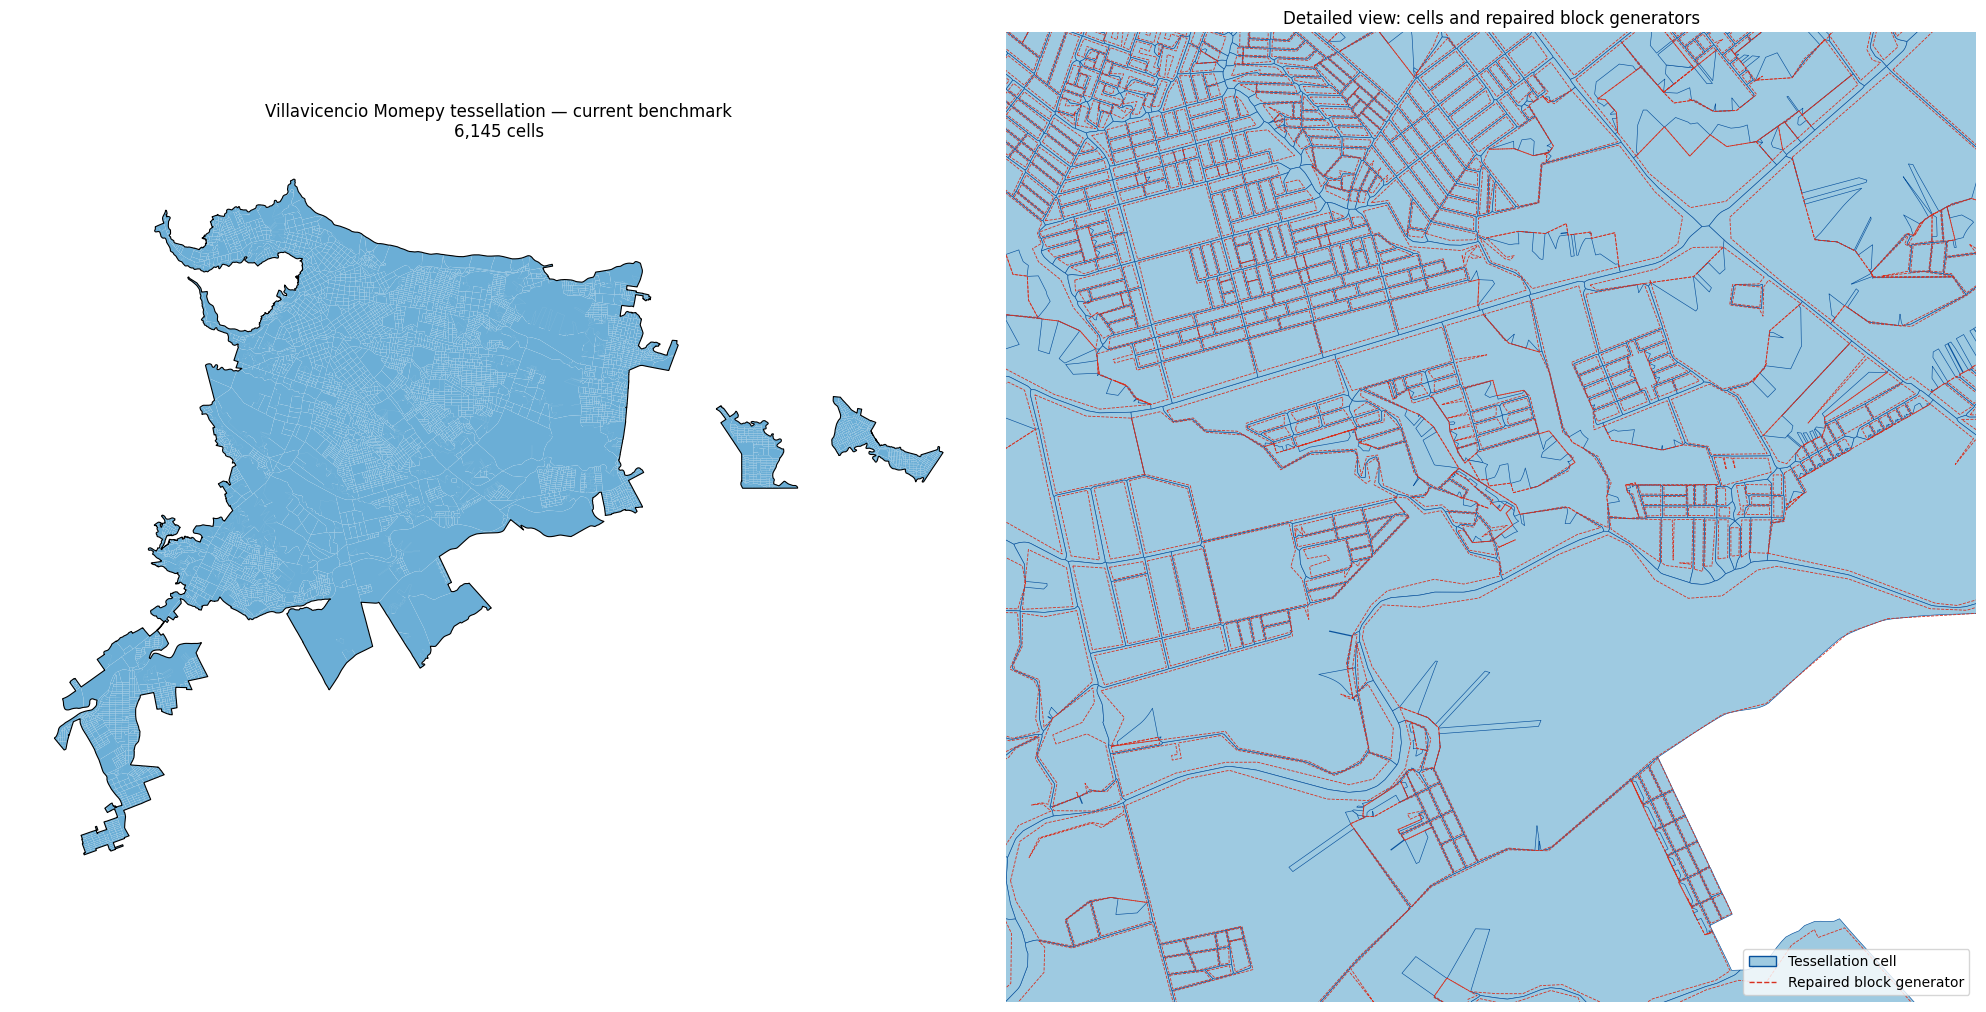

In [9]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from shapely.geometry import box

# Choose a point guaranteed to lie inside the analysis polygon.
zoom_center = city_limit.representative_point()

# A 2 km × 2 km viewport. Change this value to control the zoom.
zoom_half_width_m = 1_500

zoom_window = box(
    zoom_center.x - zoom_half_width_m,
    zoom_center.y - zoom_half_width_m,
    zoom_center.x + zoom_half_width_m,
    zoom_center.y + zoom_half_width_m,
)

tessellation_zoom = block_tessellation[
    block_tessellation.geometry.intersects(zoom_window)
]

original_blocks_zoom = block_generators[
    block_generators.geometry.intersects(zoom_window)
]

fig, (ax_city, ax_zoom) = plt.subplots(
    1,
    2,
    figsize=(20, 10),
)

# Whole analysis area
block_tessellation.plot(
    ax=ax_city,
    facecolor="#6baed6",
    edgecolor="white",
    linewidth=0.03,
)

city_polygon.boundary.plot(
    ax=ax_city,
    color="black",
    linewidth=0.8,
)

ax_city.set_title(
    f"{city_name} Momepy tessellation — current benchmark\n"
    f"{len(block_tessellation):,} cells"
)
ax_city.set_aspect("equal")
ax_city.set_axis_off()

# Detailed view
tessellation_zoom.plot(
    ax=ax_zoom,
    facecolor="#9ecae1",
    edgecolor="#08519c",
    linewidth=0.45,
)

# Overlay the topology-cleaned block footprints used as constraints.
original_blocks_zoom.boundary.plot(
    ax=ax_zoom,
    color="#d7301f",
    linewidth=0.6,
    linestyle="--",
)

ax_zoom.set_xlim(
    zoom_center.x - zoom_half_width_m,
    zoom_center.x + zoom_half_width_m,
)
ax_zoom.set_ylim(
    zoom_center.y - zoom_half_width_m,
    zoom_center.y + zoom_half_width_m,
)

ax_zoom.set_title("Detailed view: cells and repaired block generators")
ax_zoom.set_aspect("equal")
ax_zoom.set_axis_off()

legend_elements = [
    Patch(
        facecolor="#9ecae1",
        edgecolor="#08519c",
        label="Tessellation cell",
    ),
    Line2D(
        [0],
        [0],
        color="#d7301f",
        linestyle="--",
        linewidth=1,
        label="Repaired block generator",
    ),
]

ax_zoom.legend(
    handles=legend_elements,
    loc="lower right",
)

plt.tight_layout()
fig.savefig(output_dir / "01_momepy_tessellation.png", dpi=300, bbox_inches="tight")
plt.show()

In [10]:
import geopandas as gpd
import numpy as np

HEALTH_CODES = [
    "021001",
    "021002",
    "021003",
    "021004",
    "021011",
]

#These are the park codes
HEALTH_CODES = [
    "021101",
    "021102",
    "021104",
    "021105",
]

BUFFER_DISTANCE_M = 1000

city_geometry = city_polygon.geometry.union_all()
buffered_geometry = city_geometry.buffer(BUFFER_DISTANCE_M)

# Complete analysis area: selected city plus the requested extension.
city_buffered_area = gpd.GeoDataFrame(
    {
        "name": [f"{city_name} + {BUFFER_DISTANCE_M:g} m"],
        "buffer_m": [BUFFER_DISTANCE_M],
    },
    geometry=[buffered_geometry],
    crs=city_polygon.crs,
)

# Only the external buffer ring.
city_buffer_zone = gpd.GeoDataFrame(
    {"name": [f"External {BUFFER_DISTANCE_M:g} m buffer"]},
    geometry=[buffered_geometry.difference(city_geometry)],
    crs=city_polygon.crs,
)

equipment_path = (
    shape_dir
    / "colombia_equipments_ID"
    / "colombia_equipments_ID.shp"
)

# The equipment source is in WGS84. Using a mask avoids reading the
# complete national equipment dataset.
read_mask = (
    city_buffered_area
    .to_crs("EPSG:4326")
    .geometry
    .iloc[0]
)

candidate_equipment = gpd.read_file(
    equipment_path,
    mask=read_mask,
).to_crs(city_polygon.crs)

candidate_equipment["CSIMBOL"] = (
    candidate_equipment["CSIMBOL"]
    .astype("string")
    .str.strip()
)

health_centers = candidate_equipment[
    candidate_equipment["CSIMBOL"].isin(HEALTH_CODES)
].copy()

# Apply an exact spatial filter after the initial bounding-mask read.
health_centers = health_centers[
    health_centers.geometry.intersects(buffered_geometry)
].reset_index(drop=True)

# A municipality without roads was removed from the analysis polygon. Do not
# allow the 1 km external buffer to reintroduce its health centers.
if not excluded_city_urban_units.empty:
    excluded_geometry = excluded_city_urban_units.geometry.union_all()
    health_centers = health_centers[
        ~health_centers.geometry.intersects(excluded_geometry)
    ].reset_index(drop=True)

# Distinguish centers inside the city from those in the external buffer.
health_centers["inside_city"] = (
    health_centers.geometry.intersects(city_geometry)
)

health_centers["location_zone"] = np.where(
    health_centers["inside_city"],
    f"Inside {city_name} boundary",
    f"Within external {BUFFER_DISTANCE_M:g} m buffer",
)

# For outside centers, this records their shortest distance to the city.
# Centers inside the boundary receive zero.
health_centers["distance_outside_m"] = np.where(
    health_centers["inside_city"],
    0.0,
    health_centers.geometry.distance(city_geometry),
)

inside_count = int(health_centers["inside_city"].sum())
buffer_count = int((~health_centers["inside_city"]).sum())

print(f"Health centers inside {city_name}: {inside_count:,}")
print(
    f"Health centers in the external {BUFFER_DISTANCE_M:g} m buffer: "
    f"{buffer_count:,}"
)
print(f"Total health centers considered: {len(health_centers):,}")

health_centers[
    [
        "ID",
        "CSIMBOL",
        "location_zone",
        "distance_outside_m",
        "geometry",
    ]
].head()

Health centers inside Villavicencio: 248
Health centers in the external 1000 m buffer: 0
Total health centers considered: 248


,ID,CSIMBOL,location_zone,distance_outside_m,geometry
0,021101195318,021101,Inside Villavicencio boundary,0.0,POINT (649790.262 460233.934)
1,021101195329,021101,Inside Villavicencio boundary,0.0,POINT (650803.918 460186.643)
2,021101195340,021101,Inside Villavicencio boundary,0.0,POINT (649469.027 460152.503)
3,021101195341,021101,Inside Villavicencio boundary,0.0,POINT (649869.533 460153.139)
4,021101195355,021101,Inside Villavicencio boundary,0.0,POINT (649298.679 460106.749)


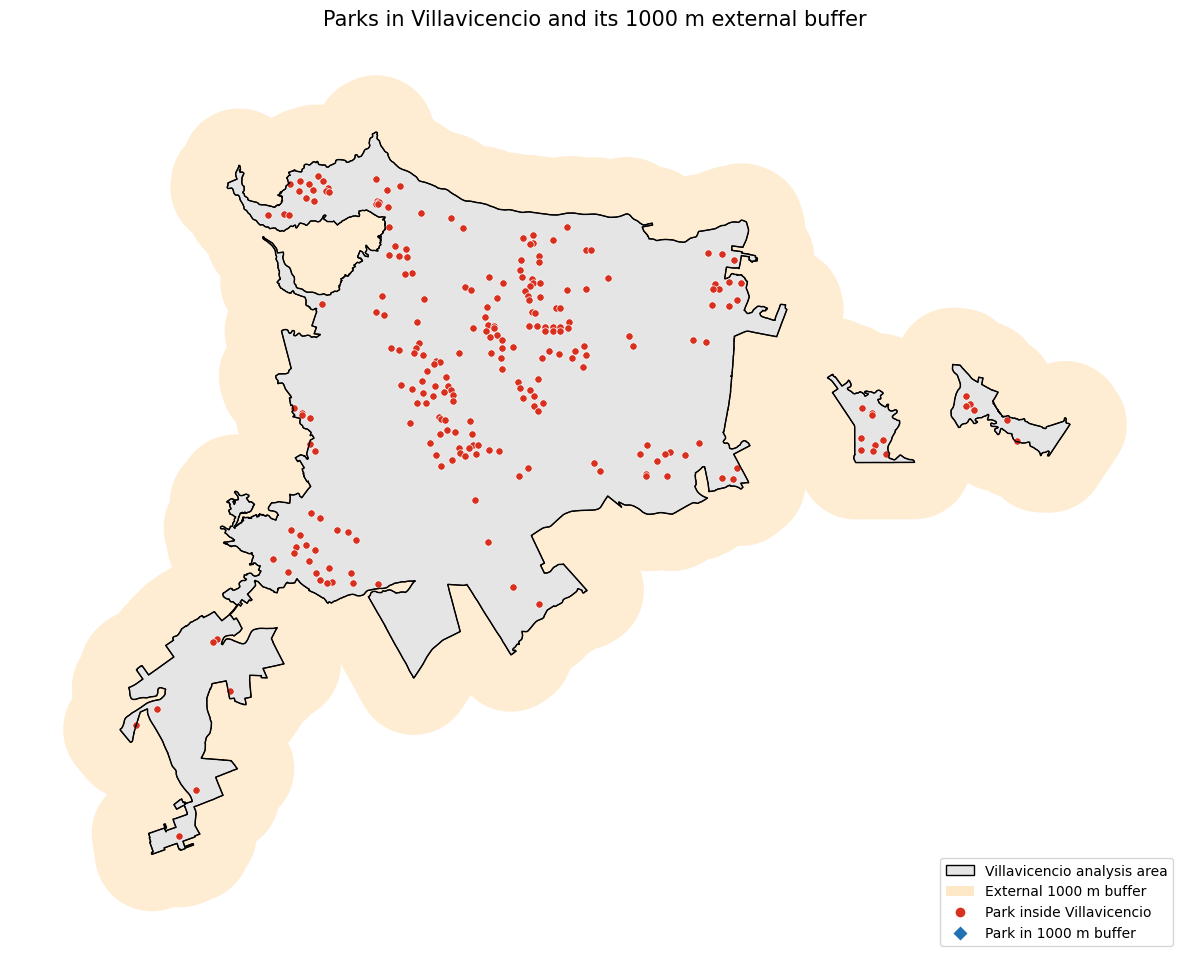

In [11]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

inside_centers = health_centers[
    health_centers["inside_city"]
]

buffer_centers = health_centers[
    ~health_centers["inside_city"]
]

fig, ax = plt.subplots(figsize=(12, 12))

# External buffer ring
city_buffer_zone.plot(
    ax=ax,
    facecolor="#fee8c8",
    edgecolor="none",
    alpha=0.8,
    zorder=1,
)

# Selected-city analysis area
city_polygon.plot(
    ax=ax,
    facecolor="#e5e5e5",
    edgecolor="black",
    linewidth=0.8,
    zorder=2,
)

# Health centers inside the city
if not inside_centers.empty:
    inside_centers.plot(
        ax=ax,
        marker="o",
        color="#d7301f",
        edgecolor="white",
        linewidth=0.5,
        markersize=28,
        zorder=4,
    )

# Health centers immediately outside the city
if not buffer_centers.empty:
    buffer_centers.plot(
        ax=ax,
        marker="D",
        color="#2171b5",
        edgecolor="white",
        linewidth=0.6,
        markersize=38,
        zorder=5,
    )

# Emphasize the original boundary over the buffer.
city_polygon.boundary.plot(
    ax=ax,
    color="black",
    linewidth=1,
    zorder=6,
)

legend_elements = [
    Patch(
        facecolor="#e5e5e5",
        edgecolor="black",
        label=f"{city_name} analysis area",
    ),
    Patch(
        facecolor="#fee8c8",
        edgecolor="none",
        label=f"External {BUFFER_DISTANCE_M:g} m buffer",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        linestyle="none",
        markerfacecolor="#d7301f",
        markeredgecolor="white",
        markersize=8,
        label=f"Park inside {city_name}",
    ),
    Line2D(
        [0],
        [0],
        marker="D",
        linestyle="none",
        markerfacecolor="#2171b5",
        markeredgecolor="white",
        markersize=8,
        label=f"Park in {BUFFER_DISTANCE_M:g} m buffer",
    ),
]

ax.legend(
    handles=legend_elements,
    loc="lower right",
    frameon=True,
)

ax.set_title(
    f"Parks in {city_name} and its {BUFFER_DISTANCE_M:g} m external buffer",
    fontsize=15,
)
ax.set_aspect("equal")
ax.set_axis_off()

plt.tight_layout()
fig.savefig(output_dir / "02_health_centers_and_buffer.png", dpi=300, bbox_inches="tight")
plt.show()

In [12]:
import networkx as nx
import numpy as np
import pandas as pd
import geopandas as gpd

from scipy.spatial import cKDTree

CONNECTOR_SPEED_M_PER_MIN = 5_000 / 60  # 5 km/h

if health_centers.empty:
    raise ValueError("No health centers are available for routing.")

if "impedance_min" not in road_edges.columns:
    raise KeyError("road_edges must contain 'impedance_min'.")

# ------------------------------------------------------------------
# Prepare network nodes
# ------------------------------------------------------------------

network_nodes = (
    road_nodes[["osmid", "geometry"]]
    .drop_duplicates(subset="osmid")
    .copy()
)

network_nodes["osmid"] = network_nodes["osmid"].astype(str)

# Keep only nodes that are actually present in the routing graph.
network_nodes = network_nodes[
    network_nodes["osmid"].isin(walking_graph.nodes)
].reset_index(drop=True)

node_ids = network_nodes["osmid"].to_numpy()

node_coordinates = np.column_stack(
    [
        network_nodes.geometry.x.to_numpy(),
        network_nodes.geometry.y.to_numpy(),
    ]
)

node_tree = cKDTree(node_coordinates)

node_geometry = network_nodes.set_index("osmid").geometry

# ------------------------------------------------------------------
# Create one centroid per tessellation cell
# ------------------------------------------------------------------

centroid_access = block_tessellation[
    ["MANZ_CCNCT", "geometry"]
].copy()

centroid_access["geometry"] = (
    centroid_access.geometry.centroid
)

centroid_access = centroid_access.set_geometry("geometry")
centroid_access.crs = block_tessellation.crs

centroid_coordinates = np.column_stack(
    [
        centroid_access.geometry.x.to_numpy(),
        centroid_access.geometry.y.to_numpy(),
    ]
)

centroid_snap_distance, centroid_node_position = node_tree.query(
    centroid_coordinates,
    k=1,
)

centroid_access["snapped_network_node"] = (
    node_ids[centroid_node_position]
)

centroid_access["centroid_snap_distance_m"] = (
    centroid_snap_distance
)

centroid_access["centroid_connector_time_min"] = (
    centroid_snap_distance / CONNECTOR_SPEED_M_PER_MIN
)

# ------------------------------------------------------------------
# Snap hospitals to the pedestrian network
# ------------------------------------------------------------------

health_routing = (
    health_centers
    .to_crs(road_nodes.crs)
    .reset_index(drop=True)
    .copy()
)

health_routing["hospital_idx"] = np.arange(
    len(health_routing),
    dtype=int,
)

hospital_coordinates = np.column_stack(
    [
        health_routing.geometry.x.to_numpy(),
        health_routing.geometry.y.to_numpy(),
    ]
)

hospital_snap_distance, hospital_node_position = node_tree.query(
    hospital_coordinates,
    k=1,
)

health_routing["network_node"] = (
    node_ids[hospital_node_position]
)

health_routing["snap_distance_m"] = hospital_snap_distance

health_routing["connector_time_min"] = (
    hospital_snap_distance / CONNECTOR_SPEED_M_PER_MIN
)

health_routing = health_routing.set_index(
    "hospital_idx",
    drop=False,
)

# ------------------------------------------------------------------
# Add one virtual source node per hospital
# ------------------------------------------------------------------
# The virtual edges allow multi-source Dijkstra to include each
# hospital's individual off-network connector time.

routing_graph = walking_graph.copy()

hospital_source_lookup = {}

for hospital in health_routing.itertuples():
    source_node = (
        "hospital_source",
        int(hospital.hospital_idx),
    )

    hospital_source_lookup[source_node] = int(
        hospital.hospital_idx
    )

    routing_graph.add_edge(
        source_node,
        hospital.network_node,
        impedance_min=float(hospital.connector_time_min),
        weight=float(hospital.connector_time_min),
        length=float(hospital.snap_distance_m),
        connector=True,
    )

hospital_sources = list(hospital_source_lookup)

# One Dijkstra search finds the closest hospital for every network node.
distance_to_hospital, paths_to_network_node = (
    nx.multi_source_dijkstra(
        routing_graph,
        sources=hospital_sources,
        weight="impedance_min",
    )
)

# ------------------------------------------------------------------
# Map routing results back to tessellation centroids
# ------------------------------------------------------------------

nearest_hospital_indices = []
network_times = []
total_times = []

for row in centroid_access.itertuples():
    snapped_node = row.snapped_network_node

    if snapped_node not in distance_to_hospital:
        nearest_hospital_indices.append(pd.NA)
        network_times.append(np.nan)
        total_times.append(np.nan)
        continue

    selected_path = paths_to_network_node[snapped_node]
    hospital_source = selected_path[0]

    hospital_idx = hospital_source_lookup[hospital_source]
    hospital_connector = health_routing.loc[
        hospital_idx,
        "connector_time_min",
    ]

    # Dijkstra distance includes the hospital connector but not the
    # centroid connector.
    distance_from_hospital = distance_to_hospital[snapped_node]

    road_network_time = max(
        0.0,
        distance_from_hospital - hospital_connector,
    )

    total_time = (
        distance_from_hospital
        + row.centroid_connector_time_min
    )

    nearest_hospital_indices.append(hospital_idx)
    network_times.append(road_network_time)
    total_times.append(total_time)

centroid_access["nearest_hospital_idx"] = pd.array(
    nearest_hospital_indices,
    dtype="Int64",
)

centroid_access["road_network_time_min"] = network_times
centroid_access["travel_time_min"] = total_times

# Attach hospital identifiers and attributes.
hospital_id_lookup = health_routing["ID"].to_dict()
hospital_code_lookup = health_routing["CSIMBOL"].to_dict()

centroid_access["nearest_hospital_ID"] = (
    centroid_access["nearest_hospital_idx"]
    .map(hospital_id_lookup)
)

centroid_access["nearest_hospital_CSIMBOL"] = (
    centroid_access["nearest_hospital_idx"]
    .map(hospital_code_lookup)
)

# Attach the accessibility results to the tessellation polygons.
access_columns = [
    "nearest_hospital_idx",
    "nearest_hospital_ID",
    "nearest_hospital_CSIMBOL",
    "snapped_network_node",
    "centroid_snap_distance_m",
    "centroid_connector_time_min",
    "road_network_time_min",
    "travel_time_min",
]

block_tessellation = (
    block_tessellation
    .drop(columns=access_columns, errors="ignore")
    .join(centroid_access[access_columns])
)

print(f"Tessellation centroids: {len(centroid_access):,}")
print(
    "Reachable centroids:",
    f"{centroid_access['travel_time_min'].notna().sum():,}",
)
print(
    "Unreachable centroids:",
    f"{centroid_access['travel_time_min'].isna().sum():,}",
)

centroid_access[
    [
        "MANZ_CCNCT",
        "nearest_hospital_ID",
        "road_network_time_min",
        "centroid_connector_time_min",
        "travel_time_min",
        "geometry",
    ]
].head()

Tessellation centroids: 6,145
Reachable centroids: 6,145
Unreachable centroids: 0


,MANZ_CCNCT,nearest_hospital_ID,road_network_time_min,centroid_connector_time_min,travel_time_min,geometry
MANZ_CCNCT,,,,,,
5000110000000001010103,5000110000000001010103,021101195565,1.203952,0.710849,2.203610,POINT (648852.767 459427.747)
5000110000000001010104,5000110000000001010104,021101195574,2.804887,0.518001,3.604292,POINT (649180.236 459431.192)
5000110000000001010105,5000110000000001010105,021101195574,2.804887,0.224801,3.311092,POINT (649203.828 459422.939)
5000110000000001010106,5000110000000001010106,021101195574,0.586661,0.630377,1.498442,POINT (649269.406 459468.258)
5000110000000001010107,5000110000000001010107,021101195574,0.229017,0.772601,1.283022,POINT (649338.241 459477.56)


In [13]:
import numpy as np
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

TIME_COLUMN = "travel_time_min"
ROUTED_TIME_COLUMN = "travel_time_min_routed"

# Always restart from the original routing output, making this cell safe to rerun.
routed_time = (
    centroid_access[TIME_COLUMN]
    .reindex(block_tessellation.index)
    .astype(float)
)
block_tessellation[ROUTED_TIME_COLUMN] = routed_time

# Queen-style adjacency: cells sharing an edge/corner are neighbors. Because
# the current benchmark has some overlapping cells, intersections also count.
neighbor_pairs = block_tessellation.sindex.query(
    block_tessellation.geometry,
    predicate="intersects",
)
left_position, right_position = neighbor_pairs
unique_pair = left_position < right_position
left_position = left_position[unique_pair]
right_position = right_position[unique_pair]

cell_count = len(block_tessellation)
adjacency = coo_matrix(
    (
        np.ones(2 * len(left_position), dtype=float),
        (
            np.concatenate([left_position, right_position]),
            np.concatenate([right_position, left_position]),
        ),
    ),
    shape=(cell_count, cell_count),
).tocsr()

neighbor_count = np.asarray(adjacency.sum(axis=1)).ravel().astype(int)
times = routed_time.to_numpy(copy=True)
observed = np.isfinite(times)
originally_missing = ~observed

# A missing connected component can be filled only if at least one cell in
# that component has an observed network-routing time.
component_count, component_label = connected_components(
    adjacency,
    directed=False,
    return_labels=True,
)
component_observed_count = np.bincount(
    component_label[observed],
    minlength=component_count,
)
component_observed_sum = np.bincount(
    component_label[observed],
    weights=times[observed],
    minlength=component_count,
)
component_has_observation = component_observed_count > 0
fillable = (
    originally_missing
    & (neighbor_count > 0)
    & component_has_observation[component_label]
)

# Initialize each fillable gap from its component mean, then solve the
# neighbor-average condition while keeping routed observations fixed.
component_mean = np.divide(
    component_observed_sum,
    component_observed_count,
    out=np.full(component_count, np.nan, dtype=float),
    where=component_observed_count > 0,
)
times[fillable] = component_mean[component_label[fillable]]

MAX_ITERATIONS = 5_000
CONVERGENCE_TOLERANCE_MIN = 1e-6
RELAXATION = 0.5
iterations = 0
maximum_change = 0.0

if fillable.any():
    for iterations in range(1, MAX_ITERATIONS + 1):
        neighbor_sum = adjacency @ np.nan_to_num(times, nan=0.0)
        neighbor_average = np.divide(
            neighbor_sum,
            neighbor_count,
            out=np.full(cell_count, np.nan, dtype=float),
            where=neighbor_count > 0,
        )
        updated = times.copy()
        updated[fillable] = (
            (1 - RELAXATION) * times[fillable]
            + RELAXATION * neighbor_average[fillable]
        )
        maximum_change = float(
            np.max(np.abs(updated[fillable] - times[fillable]))
        )
        times = updated
        if maximum_change < CONVERGENCE_TOLERANCE_MIN:
            break

block_tessellation[TIME_COLUMN] = times
block_tessellation["travel_time_imputed"] = (
    originally_missing & np.isfinite(times)
)
block_tessellation["travel_time_neighbor_count"] = neighbor_count

remaining_missing = ~np.isfinite(times)
isolated_missing = remaining_missing & (neighbor_count == 0)
unseeded_component_missing = remaining_missing & (neighbor_count > 0)

print(f"Originally blank: {originally_missing.sum():,}")
print(f"Filled from neighbors: {fillable.sum():,}")
print(f"Still blank, no polygon neighbors: {isolated_missing.sum():,}")
print(
    "Still blank, neighboring component has no routed value: "
    f"{unseeded_component_missing.sum():,}"
)
print(
    f"Neighbor averaging: {iterations:,} iterations; "
    f"maximum change={maximum_change:.8f} min"
)

block_tessellation[
    [
        "MANZ_CCNCT",
        ROUTED_TIME_COLUMN,
        TIME_COLUMN,
        "travel_time_imputed",
        "travel_time_neighbor_count",
        "geometry",
    ]
].head()

Originally blank: 0
Filled from neighbors: 0
Still blank, no polygon neighbors: 0
Still blank, neighboring component has no routed value: 0
Neighbor averaging: 0 iterations; maximum change=0.00000000 min


,MANZ_CCNCT,travel_time_min_routed,travel_time_min,travel_time_imputed,travel_time_neighbor_count,geometry
MANZ_CCNCT,,,,,,
5000110000000001010103,5000110000000001010103,2.203610,2.203610,False,7,"POLYGON ((648680.116 459472.254, 648680.048 45..."
5000110000000001010104,5000110000000001010104,3.604292,3.604292,False,9,"POLYGON ((649193.729 459328.59, 649193.397 459..."
5000110000000001010105,5000110000000001010105,3.311092,3.311092,False,3,"POLYGON ((649217.122 459408.462, 649216.645 45..."
5000110000000001010106,5000110000000001010106,1.498442,1.498442,False,7,"POLYGON ((649291.381 459411.498, 649289.675 45..."
5000110000000001010107,5000110000000001010107,1.283022,1.283022,False,5,"POLYGON ((649363.271 459423.283, 649362.681 45..."


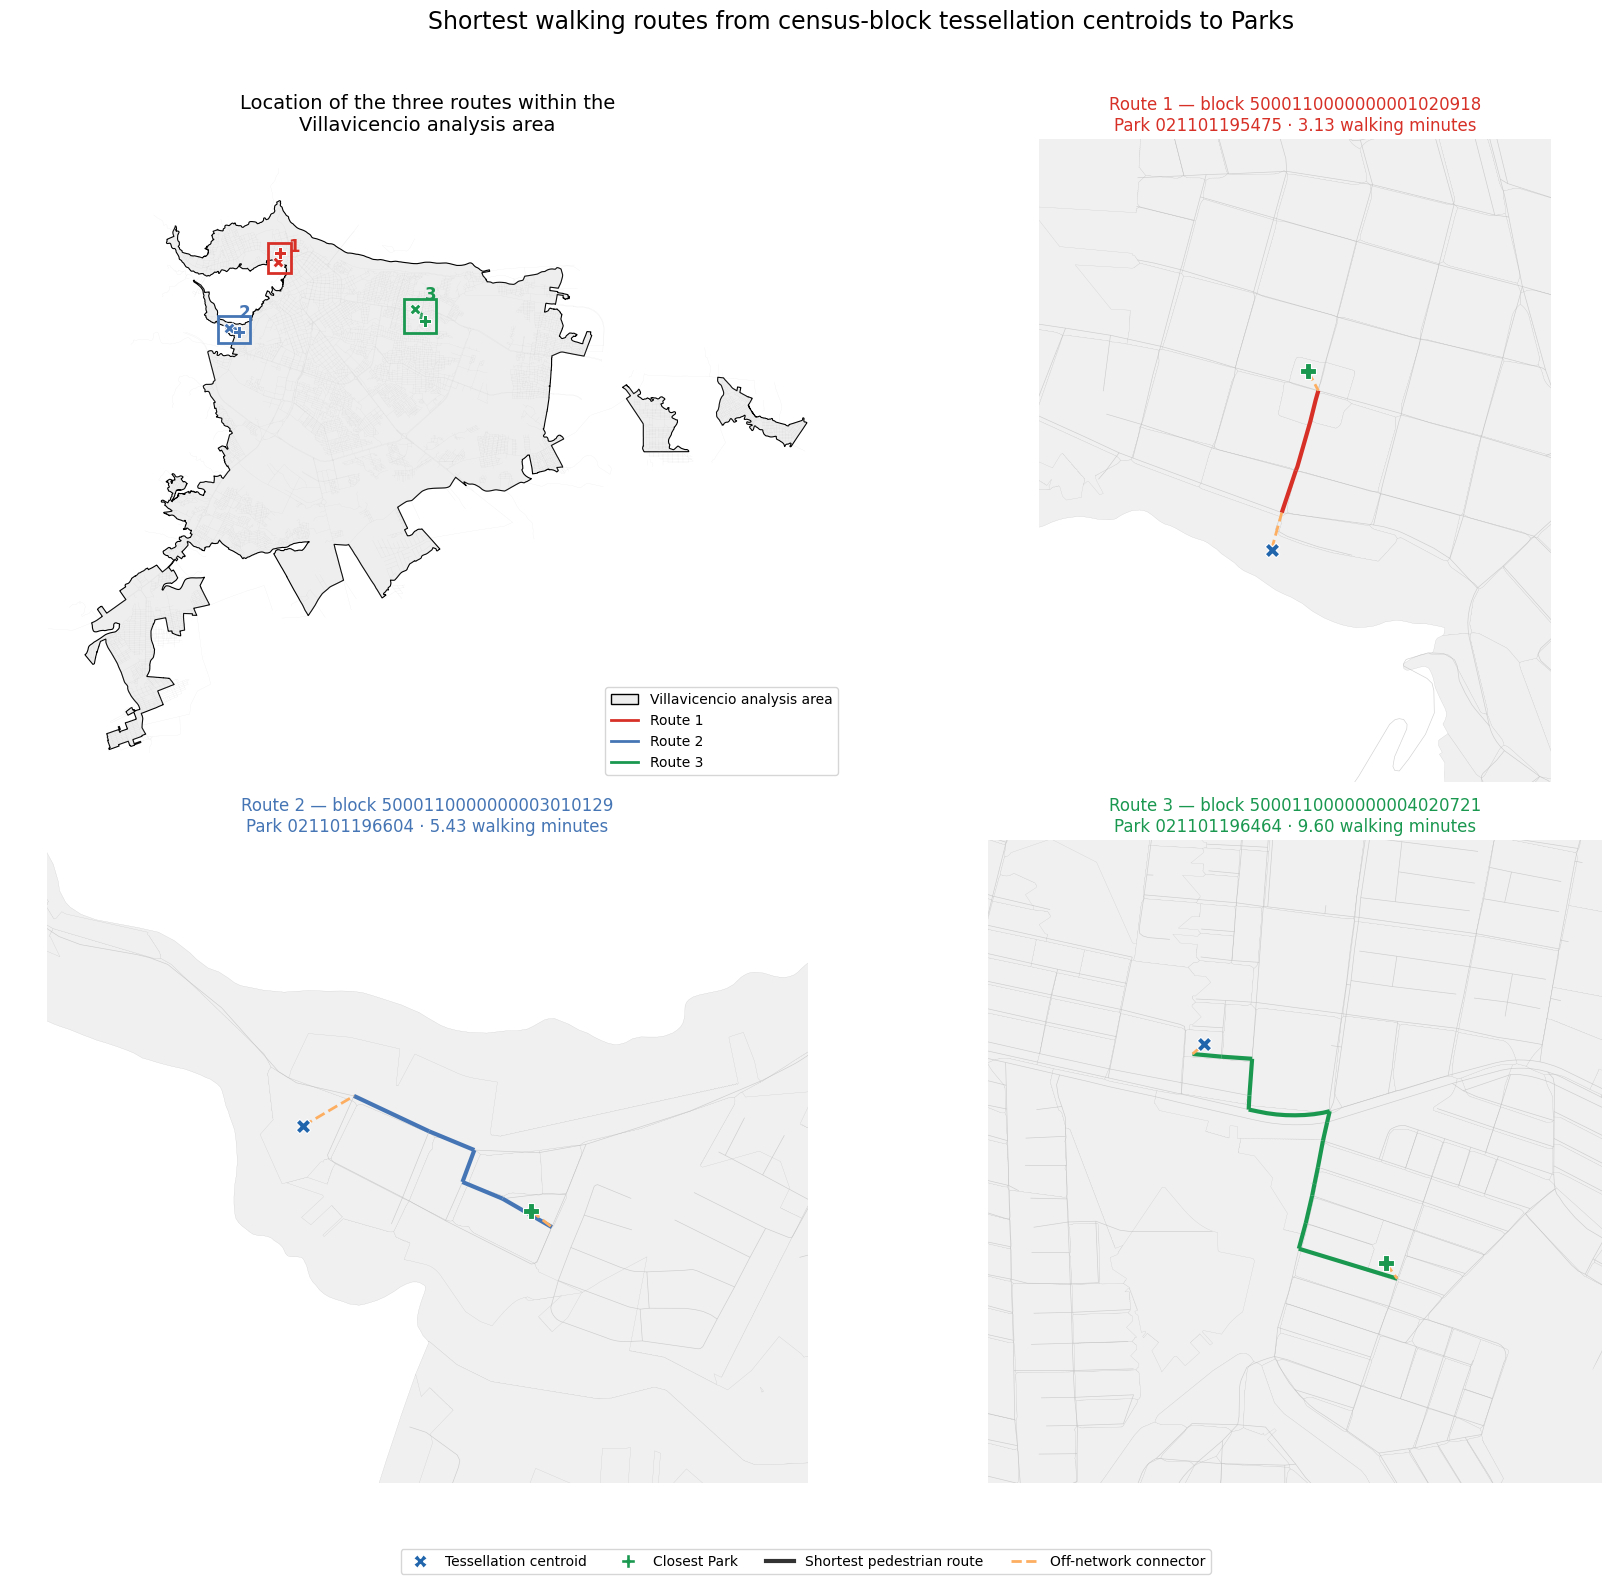

In [14]:

import matplotlib.pyplot as plt

from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from shapely.geometry import LineString, box

# ------------------------------------------------------------------
# Select three representative centroids
# ------------------------------------------------------------------

reachable = centroid_access[
    centroid_access["travel_time_min"].notna()
].copy()

if len(reachable) < 3:
    raise ValueError("At least three reachable centroids are required.")

# Select examples near the 25th, 50th and 75th travel-time percentiles.
target_times = reachable["travel_time_min"].quantile(
    [0.25, 0.50, 0.75]
)

selected_ids = []

for target_time in target_times:
    candidates = reachable[
        ~reachable.index.isin(selected_ids)
    ]

    selected_id = (
        candidates["travel_time_min"]
        .sub(target_time)
        .abs()
        .idxmin()
    )

    selected_ids.append(selected_id)

selected_centroids = reachable.loc[selected_ids]

route_colors = [
    "#d73027",
    "#4575b4",
    "#1a9850",
]

# ------------------------------------------------------------------
# Prepare routes and plotting windows
# ------------------------------------------------------------------

route_records = []

for route_number, (
    block_id,
    centroid,
) in enumerate(
    selected_centroids.iterrows(),
    start=1,
):
    hospital_idx = int(
        centroid["nearest_hospital_idx"]
    )

    hospital = health_routing.loc[hospital_idx]

    centroid_network_node = (
        centroid["snapped_network_node"]
    )

    # The first path element is the virtual hospital source.
    complete_path = paths_to_network_node[
        centroid_network_node
    ]

    route_nodes = complete_path[1:]

    route_geometries = []

    for origin_node, destination_node in zip(
        route_nodes[:-1],
        route_nodes[1:],
    ):
        edge_options = walking_graph.get_edge_data(
            origin_node,
            destination_node,
        )

        selected_edge = min(
            edge_options.values(),
            key=lambda attributes: attributes["impedance_min"],
        )

        route_geometries.append(
            selected_edge["geometry"]
        )

    route_layer = gpd.GeoDataFrame(
        geometry=route_geometries,
        crs=road_edges.crs,
    )

    # Straight-line connectors between the exact point locations
    # and their nearest pedestrian-network nodes.
    centroid_connector = LineString(
        [
            centroid.geometry,
            node_geometry.loc[centroid_network_node],
        ]
    )

    hospital_connector = LineString(
        [
            hospital.geometry,
            node_geometry.loc[hospital["network_node"]],
        ]
    )

    connector_layer = gpd.GeoDataFrame(
        geometry=[
            centroid_connector,
            hospital_connector,
        ],
        crs=road_edges.crs,
    )

    display_geometries = [
        centroid.geometry,
        hospital.geometry,
        centroid_connector,
        hospital_connector,
        *route_geometries,
    ]

    xmin, ymin, xmax, ymax = gpd.GeoSeries(
        display_geometries,
        crs=road_edges.crs,
    ).total_bounds

    route_span = max(
        xmax - xmin,
        ymax - ymin,
    )

    padding = max(
        250,
        route_span * 0.15,
    )

    view_bounds = (
        xmin - padding,
        ymin - padding,
        xmax + padding,
        ymax + padding,
    )

    view_window = box(*view_bounds)

    route_records.append(
        {
            "number": route_number,
            "block_id": block_id,
            "centroid": centroid,
            "hospital": hospital,
            "route_layer": route_layer,
            "connector_layer": connector_layer,
            "view_bounds": view_bounds,
            "view_window": view_window,
            "color": route_colors[route_number - 1],
        }
    )

# ------------------------------------------------------------------
# Create figure
# ------------------------------------------------------------------

fig, axes = plt.subplots(
    2,
    2,
    figsize=(18, 16),
)

overview_ax = axes[0, 0]
detail_axes = [
    axes[0, 1],
    axes[1, 0],
    axes[1, 1],
]

# ------------------------------------------------------------------
# City-wide reference panel
# ------------------------------------------------------------------

city_polygon.plot(
    ax=overview_ax,
    facecolor="#eeeeee",
    edgecolor="black",
    linewidth=0.8,
    zorder=1,
)

road_edges.plot(
    ax=overview_ax,
    color="#bdbdbd",
    linewidth=0.12,
    alpha=0.45,
    zorder=2,
)

overview_legend = [
    Patch(
        facecolor="#eeeeee",
        edgecolor="black",
        label=f"{city_name} analysis area",
    )
]

for record in route_records:
    color = record["color"]
    centroid = record["centroid"]
    hospital = record["hospital"]
    xmin, ymin, xmax, ymax = record["view_bounds"]

    # Complete selected route on the city map.
    if not record["route_layer"].empty:
        record["route_layer"].plot(
            ax=overview_ax,
            color=color,
            linewidth=1.8,
            zorder=4,
        )

    record["connector_layer"].plot(
        ax=overview_ax,
        color=color,
        linewidth=1,
        linestyle="--",
        zorder=4,
    )

    # Rectangle corresponding to the detailed panel.
    overview_ax.add_patch(
        Rectangle(
            (xmin, ymin),
            xmax - xmin,
            ymax - ymin,
            fill=False,
            edgecolor=color,
            linewidth=2,
            zorder=5,
        )
    )

    overview_ax.scatter(
        centroid.geometry.x,
        centroid.geometry.y,
        marker="X",
        s=65,
        color=color,
        edgecolor="white",
        linewidth=0.7,
        zorder=6,
    )

    overview_ax.scatter(
        hospital.geometry.x,
        hospital.geometry.y,
        marker="P",
        s=70,
        color=color,
        edgecolor="white",
        linewidth=0.7,
        zorder=6,
    )

    overview_ax.annotate(
        str(record["number"]),
        (
            centroid.geometry.x,
            centroid.geometry.y,
        ),
        xytext=(7, 7),
        textcoords="offset points",
        fontsize=12,
        fontweight="bold",
        color=color,
        zorder=7,
    )

    overview_legend.append(
        Line2D(
            [0],
            [0],
            color=color,
            linewidth=2,
            label=f"Route {record['number']}",
        )
    )

overview_ax.legend(
    handles=overview_legend,
    loc="lower right",
    frameon=True,
)

overview_ax.set_title(
    "Location of the three routes within the\n"
    f"{city_name} analysis area",
    fontsize=14,
)
overview_ax.set_aspect("equal")
overview_ax.set_axis_off()

# ------------------------------------------------------------------
# Detailed route panels
# ------------------------------------------------------------------

for ax, record in zip(
    detail_axes,
    route_records,
):
    centroid = record["centroid"]
    hospital = record["hospital"]
    color = record["color"]

    xmin, ymin, xmax, ymax = record["view_bounds"]

    local_roads = road_edges[
        road_edges.geometry.intersects(
            record["view_window"]
        )
    ]

    local_cells = block_tessellation[
        block_tessellation.geometry.intersects(
            record["view_window"]
        )
    ]

    local_cells.plot(
        ax=ax,
        facecolor="#f0f0f0",
        edgecolor="#bdbdbd",
        linewidth=0.15,
        zorder=1,
    )

    local_roads.plot(
        ax=ax,
        color="#bdbdbd",
        linewidth=0.45,
        alpha=0.7,
        zorder=2,
    )

    if not record["route_layer"].empty:
        record["route_layer"].plot(
            ax=ax,
            color=color,
            linewidth=3,
            zorder=4,
        )

    record["connector_layer"].plot(
        ax=ax,
        color="#fdae61",
        linewidth=2,
        linestyle="--",
        zorder=5,
    )

    ax.scatter(
        centroid.geometry.x,
        centroid.geometry.y,
        marker="X",
        s=110,
        color="#2166ac",
        edgecolor="white",
        linewidth=0.8,
        zorder=6,
    )

    ax.scatter(
        hospital.geometry.x,
        hospital.geometry.y,
        marker="P",
        s=120,
        color="#1a9850",
        edgecolor="white",
        linewidth=0.8,
        zorder=6,
    )

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")
    ax.set_axis_off()

    ax.set_title(
        f"Route {record['number']} — block {record['block_id']}\n"
        f"Park {hospital['ID']} · "
        f"{centroid['travel_time_min']:.2f} walking minutes",
        color=color,
        fontsize=12,
    )

# ------------------------------------------------------------------
# Shared legend
# ------------------------------------------------------------------

detail_legend = [
    Line2D(
        [0],
        [0],
        marker="X",
        linestyle="none",
        markerfacecolor="#2166ac",
        markeredgecolor="white",
        markersize=10,
        label="Tessellation centroid",
    ),
    Line2D(
        [0],
        [0],
        marker="P",
        linestyle="none",
        markerfacecolor="#1a9850",
        markeredgecolor="white",
        markersize=10,
        label="Closest Park",
    ),
    Line2D(
        [0],
        [0],
        color="#333333",
        linewidth=3,
        label="Shortest pedestrian route",
    ),
    Line2D(
        [0],
        [0],
        color="#fdae61",
        linewidth=2,
        linestyle="--",
        label="Off-network connector",
    ),
]

fig.legend(
    handles=detail_legend,
    loc="lower center",
    ncol=4,
    frameon=True,
)

fig.suptitle(
    "Shortest walking routes from census-block tessellation "
    "centroids to Parks",
    fontsize=17,
    y=0.98,
)

plt.tight_layout(
    rect=(0, 0.05, 1, 0.96)
)
fig.savefig(output_dir / "03_example_shortest_routes.png", dpi=300, bbox_inches="tight")
plt.show()


In [15]:
import numpy as np
import gudhi
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

# ------------------------------------------------------------------
# Parameters
# ------------------------------------------------------------------
TIME_COLUMN = "travel_time_min"
T_START = 60.0           # filtration starts here and decreases
ADJ_TOL_M = 0.5          # cells closer than this count as adjacent (queen + tolerance)
MAX_SIMPLEX_DIM = 2      # the 2-skeleton is enough for H0 and H1

# ------------------------------------------------------------------
# Function on cells, clipped at T_START
# Superlevel set of f  ==  sublevel set of g = -f
# ------------------------------------------------------------------
f_all = block_tessellation[TIME_COLUMN].to_numpy(dtype=float)
valid = np.isfinite(f_all)                      # drops the one isolated NaN cell
f = np.minimum(f_all[valid], T_START)
g = -f
n_cells = int(valid.sum())
n_clipped = int((f_all[valid] > T_START).sum())

# ------------------------------------------------------------------
# Adjacency graph of the cells (the 1-skeleton of the nerve)
# ------------------------------------------------------------------
left, right = block_tessellation.sindex.query(
    block_tessellation.geometry,
    predicate="dwithin",
    distance=ADJ_TOL_M,
)
unique_pair = left < right
left, right = left[unique_pair], right[unique_pair]

new_index = np.full(len(f_all), -1, dtype=int)
new_index[valid] = np.arange(n_cells)
edge_i, edge_j = new_index[left], new_index[right]
both_valid = (edge_i >= 0) & (edge_j >= 0)
edge_i, edge_j = edge_i[both_valid], edge_j[both_valid]

# ------------------------------------------------------------------
# Filtered clique complex: a simplex enters at the max of g over its
# vertices, i.e. the min of f. Cells with f >= T_START enter together.
# ------------------------------------------------------------------
simplex_tree = gudhi.SimplexTree()
for vertex, value in enumerate(g):
    simplex_tree.insert([vertex], filtration=float(value))
for a, b in zip(edge_i, edge_j):
    simplex_tree.insert([int(a), int(b)], filtration=float(max(g[a], g[b])))

simplex_tree.expansion(MAX_SIMPLEX_DIM)
simplex_tree.make_filtration_non_decreasing()
simplex_tree.compute_persistence(homology_coeff_field=2, min_persistence=0.0)

# ------------------------------------------------------------------
# Convert back to walking-time units: [birth_t, death_t], birth_t > death_t.
# Essential classes get death_t = -inf (they never die).
# ------------------------------------------------------------------
superlevel_diagrams = {}
for dim in (0, 1):
    pairs = np.asarray(
        simplex_tree.persistence_intervals_in_dimension(dim), dtype=float
    ).reshape(-1, 2)
    superlevel_diagrams[dim] = -pairs
    pd.DataFrame(
        superlevel_diagrams[dim],
        columns=["birth_min", "death_min"],
    ).to_csv(
        output_dir / f"superlevel_h{dim}_persistence.csv",
        index=False,
    )

print(f"Saved raw superlevel H0/H1 diagrams to {output_dir}")

# ------------------------------------------------------------------
# Sanity checks and summary
# ------------------------------------------------------------------
adjacency = coo_matrix(
    (np.ones(len(edge_i)), (edge_i, edge_j)), shape=(n_cells, n_cells)
)
n_components, _ = connected_components(adjacency, directed=False)

print(f"Cells used: {n_cells:,}  (clipped at {T_START:g} min: {n_clipped:,})")
print(f"Adjacency edges: {len(edge_i):,}")
print(f"Simplices in complex: {simplex_tree.num_simplices():,}")
print(f"Connected components of adjacency graph: {n_components}")

for dim, diagram in superlevel_diagrams.items():
    essential = ~np.isfinite(diagram[:, 1])
    lifetimes = diagram[~essential, 0] - diagram[~essential, 1]
    print(f"\nH{dim}: {len(diagram):,} classes ({essential.sum()} essential)")
    if len(lifetimes):
        top = np.sort(lifetimes)[::-1][:5]
        print("  largest finite lifetimes (min):", np.round(top, 2))

essential_h0 = int((~np.isfinite(superlevel_diagrams[0][:, 1])).sum())
if essential_h0 != n_components:
    print(
        f"\nWARNING: {essential_h0} essential H0 classes but {n_components} "
        "adjacency components; check the adjacency tolerance."
    )

Saved raw superlevel H0/H1 diagrams to /Users/gregorioperez/Documents/Maestria/Investigacion/urban_form/pedestrian_accessibility/level_sets_blocks/results/experiment_1_complete_cities/persitent_parks_raw/villavicencio
Cells used: 6,145  (clipped at 60 min: 0)
Adjacency edges: 18,295
Simplices in complex: 37,459
Connected components of adjacency graph: 3

H0: 460 classes (3 essential)
  largest finite lifetimes (min): [43.55 41.13 35.03 22.94 21.2 ]

H1: 377 classes (1 essential)
  largest finite lifetimes (min): [15.09 13.92  8.48  7.94  7.36]


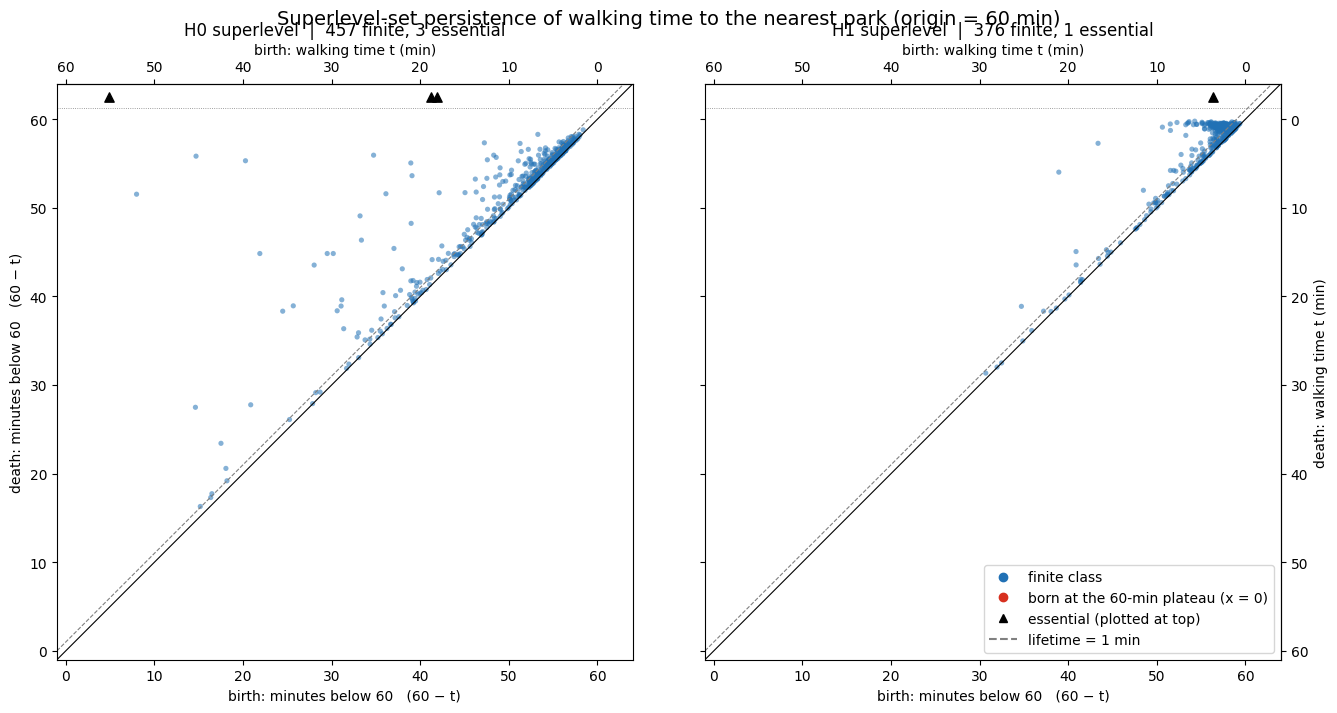

In [16]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

NOISE_FLOOR_MIN = 1.0    # centroid-snapping noise; dashed line marks this lifetime

# ------------------------------------------------------------------
# Descent coordinates: the origin (0, 0) is t = T_START (60 min).
#   x = T_START - birth      y = T_START - death
# so every class sits above the diagonal, as in a standard diagram.
# Essential classes (death = -inf) are drawn on a reserved row at the top.
# ------------------------------------------------------------------
to_descent = lambda t: T_START - t
from_descent = lambda u: T_START - u

finite_pairs = np.concatenate([
    to_descent(d[np.isfinite(d[:, 1])]) for d in superlevel_diagrams.values() if len(d)
])
data_max = finite_pairs.max() if len(finite_pairs) else 10.0
axis_low = -1.0
axis_high = np.ceil(data_max) + 4
essential_row = axis_high - 1.5          # essential classes sit near the top

fig, axes = plt.subplots(1, 2, figsize=(14, 7), sharex=True, sharey=True)

for ax, (dim, diagram) in zip(axes, superlevel_diagrams.items()):
    essential = ~np.isfinite(diagram[:, 1])
    finite = to_descent(diagram[~essential])          # columns: (x, y) = (birth, death) in descent units
    on_plateau = np.isclose(finite[:, 0], 0.0)        # born at T_START: the clipped plateau

    # Diagonal and noise band (classes between the two lines are within the noise floor)
    grid = np.array([axis_low, axis_high])
    ax.plot(grid, grid, color="black", linewidth=0.8)
    ax.plot(grid, grid + NOISE_FLOOR_MIN, color="grey", linestyle="--", linewidth=0.8)
    ax.axhline(essential_row - 1.2, color="grey", linestyle=":", linewidth=0.6)

    ax.scatter(finite[~on_plateau, 0], finite[~on_plateau, 1],
               s=14, alpha=0.55, color="#2171b5", edgecolor="none")
    ax.scatter(finite[on_plateau, 0], finite[on_plateau, 1],
               s=22, alpha=0.8, color="#d7301f", edgecolor="none")
    ax.scatter(to_descent(diagram[essential, 0]), np.full(essential.sum(), essential_row),
               marker="^", s=45, color="black")

    ax.set_xlim(axis_low, axis_high)
    ax.set_ylim(axis_low, axis_high)
    ax.set_aspect("equal")
    ax.set_xlabel(f"birth: minutes below {T_START:g}   ({T_START:g} − t)")
    ax.set_title(f"H{dim} superlevel  |  {len(finite):,} finite, {essential.sum()} essential")

    # real walking times along the top edge
    top = ax.secondary_xaxis("top", functions=(from_descent, to_descent))
    top.set_xlabel("birth: walking time t (min)")

axes[0].set_ylabel(f"death: minutes below {T_START:g}   ({T_START:g} − t)")
right = axes[1].secondary_yaxis("right", functions=(from_descent, to_descent))
right.set_ylabel("death: walking time t (min)")

legend_elements = [
    Line2D([0], [0], marker="o", linestyle="none", color="#2171b5", label="finite class"),
    Line2D([0], [0], marker="o", linestyle="none", color="#d7301f",
           label=f"born at the {T_START:g}-min plateau (x = 0)"),
    Line2D([0], [0], marker="^", linestyle="none", color="black",
           label="essential (plotted at top)"),
    Line2D([0], [0], color="grey", linestyle="--",
           label=f"lifetime = {NOISE_FLOOR_MIN:g} min"),
]
axes[1].legend(handles=legend_elements, loc="lower right", frameon=True)

fig.suptitle("Superlevel-set persistence of walking time to the nearest park "
             f"(origin = {T_START:g} min)", fontsize=14)
plt.tight_layout()
fig.savefig(output_dir / "04_superlevel_persistence_diagrams.png", dpi=300, bbox_inches="tight")
plt.show()

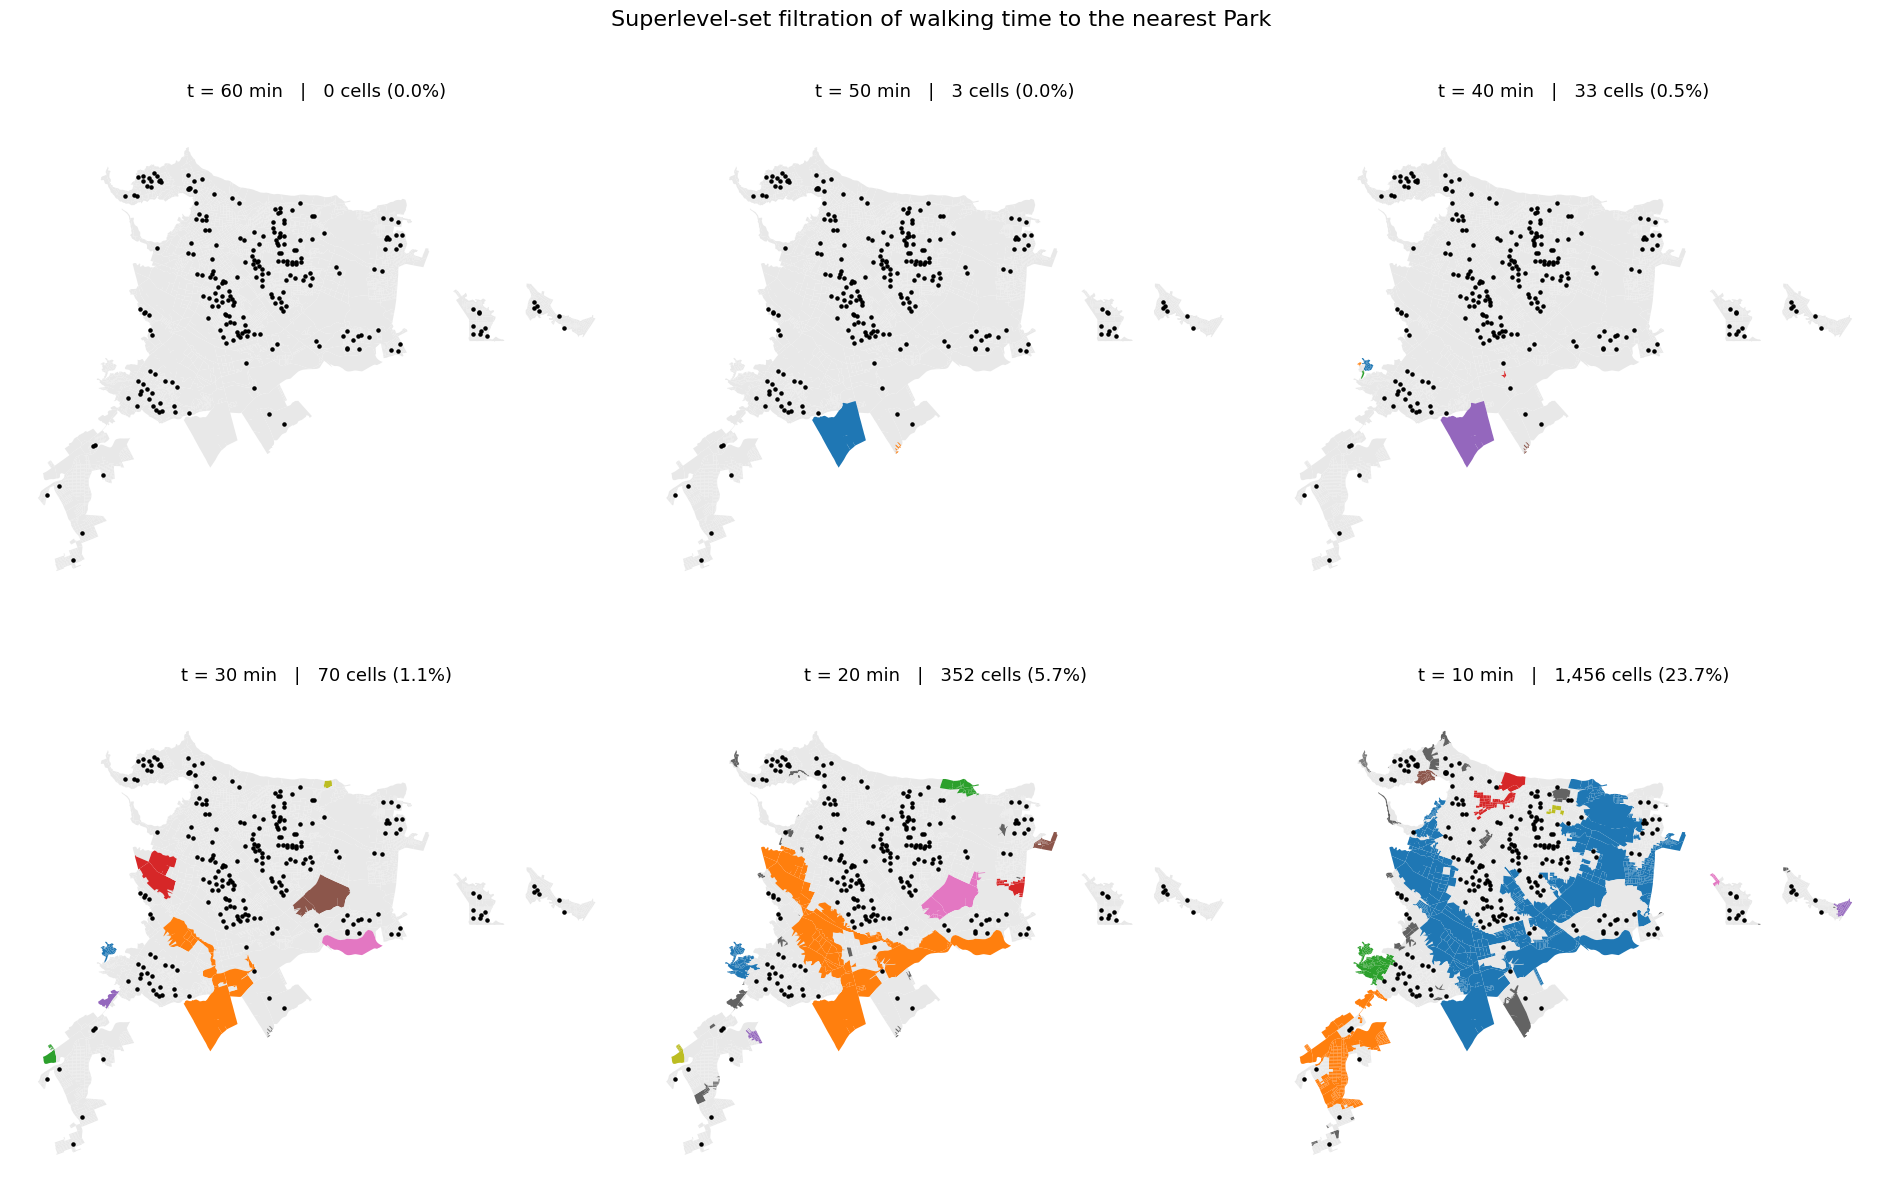

In [17]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

# ------------------------------------------------------------------
# Parameters
# ------------------------------------------------------------------
SNAPSHOT_TIMES = [60, 50, 40, 30, 20, 10]       # decreasing; edit to taste
# Data-driven alternative (equal fractions of the city active):
# SNAPSHOT_TIMES = np.quantile(f, [0.99, 0.8, 0.6, 0.4, 0.2, 0.05])[::-1]

N_DISTINCT_COMPONENTS = 9      # largest components get their own color
INACTIVE_COLOR = "#e8e8e8"
SMALL_COMPONENT_COLOR = "#636363"
SHOW_HOSPITALS = True
XLIM, YLIM = None, None        # e.g. (435_000, 445_000) to zoom into a window

assert len(SNAPSHOT_TIMES) == 6, "This layout expects exactly 6 snapshots."

# Cells in the same order as the filtration vertices
cells = block_tessellation[valid]
palette = plt.get_cmap("tab10")
distinct_colors = [to_hex(palette(k)) for k in range(N_DISTINCT_COMPONENTS)]

def betti_at(diagram, t):
    """Classes alive in the superlevel set {f >= t}: birth >= t > death."""
    return int(((diagram[:, 0] >= t) & (diagram[:, 1] < t)).sum())

# ------------------------------------------------------------------
# Figure
# ------------------------------------------------------------------
fig, axes = plt.subplots(2, 3, figsize=(19, 13))

for ax, t in zip(axes.ravel(), SNAPSHOT_TIMES):
    active = f >= t

    # Connected components of the active subgraph
    edge_active = active[edge_i] & active[edge_j]
    subgraph = coo_matrix(
        (np.ones(edge_active.sum()), (edge_i[edge_active], edge_j[edge_active])),
        shape=(n_cells, n_cells),
    )
    _, labels = connected_components(subgraph, directed=False)

    # Rank components (active cells only) by size and assign colors
    colors = np.full(n_cells, INACTIVE_COLOR, dtype=object)
    if active.any():
        active_labels, sizes = np.unique(labels[active], return_counts=True)
        ranked = active_labels[np.argsort(sizes)[::-1]]
        color_of = {
            label: (distinct_colors[rank] if rank < N_DISTINCT_COMPONENTS
                    else SMALL_COMPONENT_COLOR)
            for rank, label in enumerate(ranked)
        }
        colors[active] = [color_of[label] for label in labels[active]]
        n_components = len(active_labels)
    else:
        n_components = 0

    cells.plot(ax=ax, color=list(colors), linewidth=0)

    if SHOW_HOSPITALS:
        health_centers.plot(ax=ax, color="black", markersize=5, zorder=3)

    if XLIM is not None:
        ax.set_xlim(XLIM)
    if YLIM is not None:
        ax.set_ylim(YLIM)

    b0 = betti_at(superlevel_diagrams[0], t)
    b1 = betti_at(superlevel_diagrams[1], t)
    ax.set_title(
        f"t = {t:g} min   |   {active.sum():,} cells ({100 * active.mean():.1f}%)\n",
        fontsize=13,
    )
    ax.set_aspect("equal")
    ax.set_axis_off()

    if b0 != n_components:
        print(f"t = {t:g}: β0 from diagram = {b0}, components in graph = {n_components}")

fig.suptitle(
    "Superlevel-set filtration of walking time to the nearest Park ",
    fontsize=16,
)
plt.tight_layout()
fig.savefig(output_dir / "05_superlevel_filtration.png", dpi=300, bbox_inches="tight")
plt.show()

In [18]:
import numpy as np
import gudhi
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

# ------------------------------------------------------------------
# Parameters
# ------------------------------------------------------------------
T_END = 60.0             # same clipped function as the superlevel run; None = raw maximum
MAX_SIMPLEX_DIM = 2      # the 2-skeleton is enough for H0 and H1

# ------------------------------------------------------------------
# Function on cells (sublevel set {f <= t}, so the values enter as they are)
# ------------------------------------------------------------------
f_raw = f_all[valid]
if T_END is None:
    f_sub = f_raw.copy()
    n_clipped_sub = 0
else:
    f_sub = np.minimum(f_raw, T_END)
    n_clipped_sub = int((f_raw > T_END).sum())

# ------------------------------------------------------------------
# Filtered clique complex: a simplex enters at the max of f over its vertices
# ------------------------------------------------------------------
simplex_tree_sub = gudhi.SimplexTree()
for vertex, value in enumerate(f_sub):
    simplex_tree_sub.insert([vertex], filtration=float(value))
for a, b in zip(edge_i, edge_j):
    simplex_tree_sub.insert([int(a), int(b)], filtration=float(max(f_sub[a], f_sub[b])))

simplex_tree_sub.expansion(MAX_SIMPLEX_DIM)
simplex_tree_sub.make_filtration_non_decreasing()
simplex_tree_sub.compute_persistence(homology_coeff_field=2, min_persistence=0.0)

# Diagrams as [birth_t, death_t] with birth_t < death_t; essential classes have death = inf
sublevel_diagrams = {}
for dim in (0, 1):
    sublevel_diagrams[dim] = np.asarray(
        simplex_tree_sub.persistence_intervals_in_dimension(dim), dtype=float
    ).reshape(-1, 2)
    pd.DataFrame(
        sublevel_diagrams[dim],
        columns=["birth_min", "death_min"],
    ).to_csv(
        output_dir / f"sublevel_h{dim}_persistence.csv",
        index=False,
    )

print(f"Saved raw sublevel H0/H1 diagrams to {output_dir}")

# ------------------------------------------------------------------
# Sanity checks and summary
# ------------------------------------------------------------------
adjacency_sub = coo_matrix(
    (np.ones(len(edge_i)), (edge_i, edge_j)), shape=(n_cells, n_cells)
)
n_components_sub, _ = connected_components(adjacency_sub, directed=False)

print(f"Cells used: {n_cells:,}  (clipped at {T_END}: {n_clipped_sub:,})")
print(f"Simplices in complex: {simplex_tree_sub.num_simplices():,}")
print(f"Connected components of adjacency graph: {n_components_sub}")

for dim, diagram in sublevel_diagrams.items():
    essential = ~np.isfinite(diagram[:, 1])
    lifetimes = diagram[~essential, 1] - diagram[~essential, 0]
    print(f"\nH{dim}: {len(diagram):,} classes ({essential.sum()} essential)")
    if len(lifetimes):
        top = np.sort(lifetimes)[::-1][:5]
        print("  largest finite lifetimes (min):", np.round(top, 2))

essential_h0_sub = int((~np.isfinite(sublevel_diagrams[0][:, 1])).sum())
if essential_h0_sub != n_components_sub:
    print(
        f"\nWARNING: {essential_h0_sub} essential H0 classes but {n_components_sub} "
        "adjacency components; check the adjacency tolerance."
    )
print(f"\nFor reference: {len(health_centers)} health centers in the analysis area.")

Saved raw sublevel H0/H1 diagrams to /Users/gregorioperez/Documents/Maestria/Investigacion/urban_form/pedestrian_accessibility/level_sets_blocks/results/experiment_1_complete_cities/persitent_parks_raw/villavicencio
Cells used: 6,145  (clipped at 60.0: 0)
Simplices in complex: 37,459
Connected components of adjacency graph: 3

H0: 439 classes (3 essential)
  largest finite lifetimes (min): [39.4  21.35 20.96 19.8  19.52]

H1: 342 classes (1 essential)
  largest finite lifetimes (min): [22.94 12.65 10.38  7.84  6.89]

For reference: 248 health centers in the analysis area.


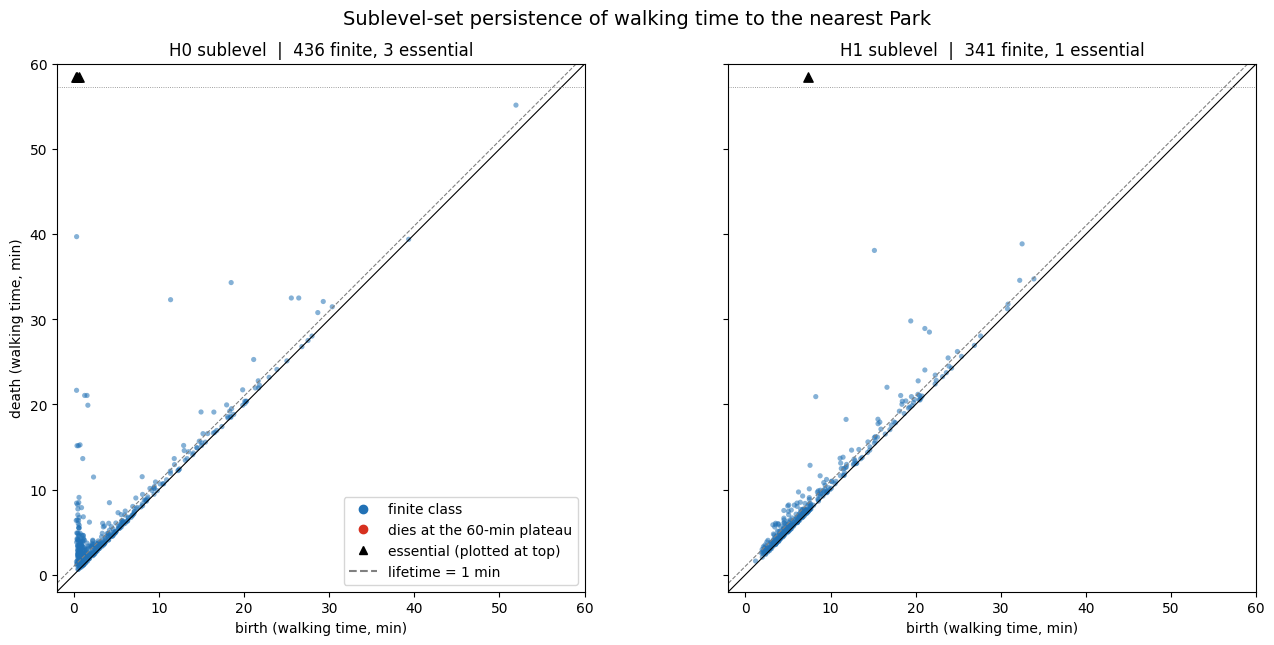

In [19]:
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

NOISE_FLOOR_MIN = 1.0    # centroid-snapping noise; dashed line marks this lifetime

finite_values = np.concatenate([
    d[np.isfinite(d[:, 1])].ravel()
    for d in sublevel_diagrams.values() if len(d)
])
axis_low = np.floor(finite_values.min()) - 2
axis_high = np.ceil(finite_values.max()) + 4
essential_row = axis_high - 1.5          # essential classes are drawn near the top

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5), sharex=True, sharey=True)

for ax, (dim, diagram) in zip(axes, sublevel_diagrams.items()):
    essential = ~np.isfinite(diagram[:, 1])
    finite = diagram[~essential]
    if T_END is None:
        on_plateau = np.zeros(len(finite), dtype=bool)
    else:
        on_plateau = np.isclose(finite[:, 1], T_END)   # killed when the clipped plateau appears

    grid = np.array([axis_low, axis_high])
    ax.plot(grid, grid, color="black", linewidth=0.8)
    ax.plot(grid, grid + NOISE_FLOOR_MIN, color="grey", linestyle="--", linewidth=0.8)
    ax.axhline(essential_row - 1.2, color="grey", linestyle=":", linewidth=0.6)

    ax.scatter(
        finite[~on_plateau, 0], finite[~on_plateau, 1],
        s=14, alpha=0.55, color="#2171b5", edgecolor="none",
    )
    ax.scatter(
        finite[on_plateau, 0], finite[on_plateau, 1],
        s=22, alpha=0.8, color="#d7301f", edgecolor="none",
    )
    ax.scatter(
        diagram[essential, 0], np.full(essential.sum(), essential_row),
        marker="^", s=45, color="black",
    )

    ax.set_xlim(axis_low, axis_high)
    ax.set_ylim(axis_low, axis_high)
    ax.set_aspect("equal")
    ax.set_xlabel("birth (walking time, min)")
    ax.set_title(
        f"H{dim} sublevel  |  {len(finite):,} finite, {essential.sum()} essential"
    )

axes[0].set_ylabel("death (walking time, min)")

legend_elements = [
    Line2D([0], [0], marker="o", linestyle="none", color="#2171b5", label="finite class"),
    Line2D([0], [0], marker="^", linestyle="none", color="black",
           label="essential (plotted at top)"),
    Line2D([0], [0], color="grey", linestyle="--",
           label=f"lifetime = {NOISE_FLOOR_MIN:g} min"),
]
if T_END is not None:
    legend_elements.insert(1, Line2D(
        [0], [0], marker="o", linestyle="none", color="#d7301f",
        label=f"dies at the {T_END:g}-min plateau",
    ))
axes[0].legend(handles=legend_elements, loc="lower right", frameon=True)

fig.suptitle("Sublevel-set persistence of walking time to the nearest Park", fontsize=14)
plt.tight_layout()
fig.savefig(output_dir / "06_sublevel_persistence_diagrams.png", dpi=300, bbox_inches="tight")
plt.show()

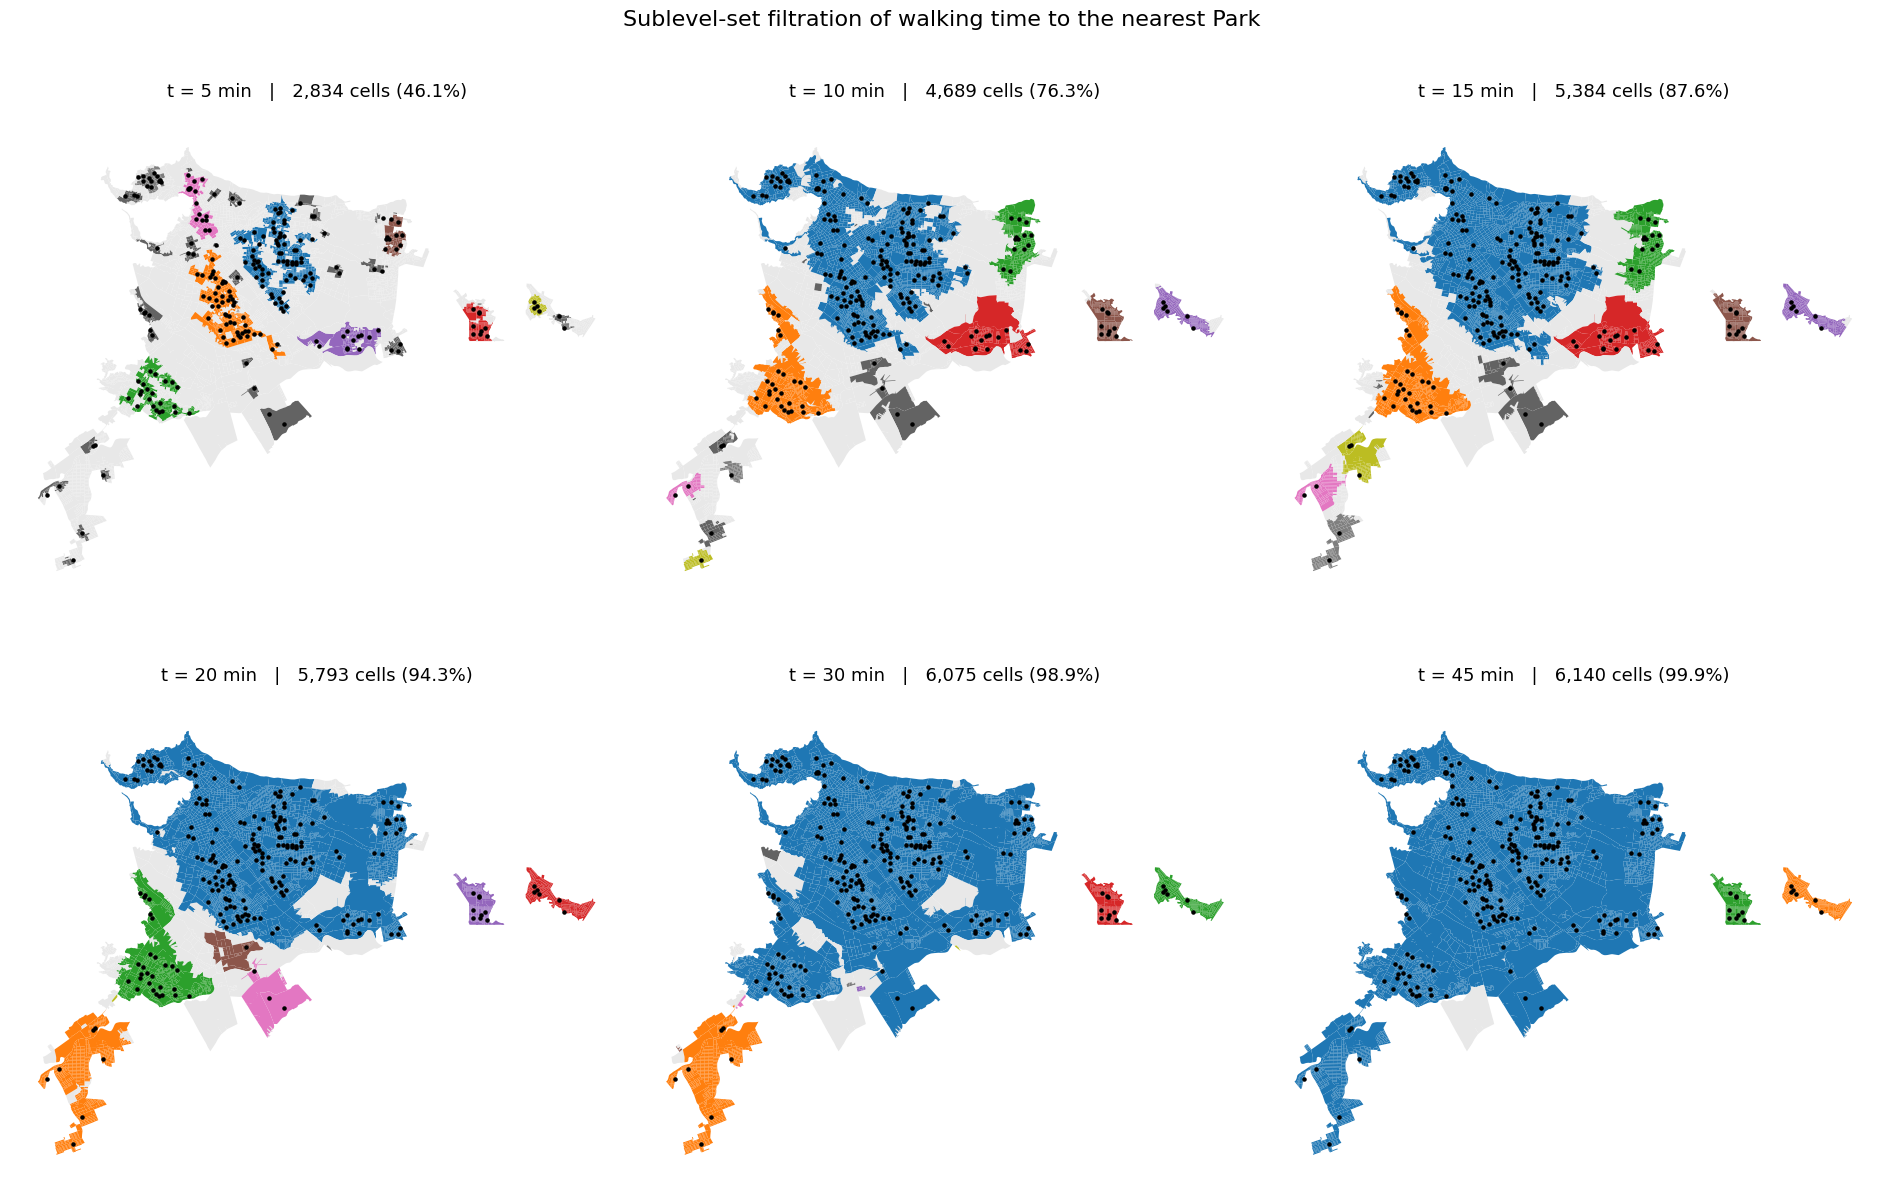

In [20]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import to_hex
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

# ------------------------------------------------------------------
# Parameters
# ------------------------------------------------------------------
SNAPSHOT_TIMES = [5, 10, 15, 20, 30, 45]        # increasing; edit to taste
# Data-driven alternative (equal fractions of the city active):
# SNAPSHOT_TIMES = np.quantile(f_sub, [0.05, 0.2, 0.4, 0.6, 0.8, 0.95])

N_DISTINCT_COMPONENTS = 9
INACTIVE_COLOR = "#e8e8e8"
SMALL_COMPONENT_COLOR = "#636363"
SHOW_HOSPITALS = True
XLIM, YLIM = None, None

assert len(SNAPSHOT_TIMES) == 6, "This layout expects exactly 6 snapshots."

cells = block_tessellation[valid]
palette = plt.get_cmap("tab10")
distinct_colors = [to_hex(palette(k)) for k in range(N_DISTINCT_COMPONENTS)]

def betti_at_sub(diagram, t):
    """Classes alive in the sublevel set {f <= t}: birth <= t < death."""
    return int(((diagram[:, 0] <= t) & (diagram[:, 1] > t)).sum())

fig, axes = plt.subplots(2, 3, figsize=(19, 13))

for ax, t in zip(axes.ravel(), SNAPSHOT_TIMES):
    active = f_sub <= t

    edge_active = active[edge_i] & active[edge_j]
    subgraph = coo_matrix(
        (np.ones(edge_active.sum()), (edge_i[edge_active], edge_j[edge_active])),
        shape=(n_cells, n_cells),
    )
    _, labels = connected_components(subgraph, directed=False)

    colors = np.full(n_cells, INACTIVE_COLOR, dtype=object)
    if active.any():
        active_labels, sizes = np.unique(labels[active], return_counts=True)
        ranked = active_labels[np.argsort(sizes)[::-1]]
        color_of = {
            label: (distinct_colors[rank] if rank < N_DISTINCT_COMPONENTS
                    else SMALL_COMPONENT_COLOR)
            for rank, label in enumerate(ranked)
        }
        colors[active] = [color_of[label] for label in labels[active]]
        n_components = len(active_labels)
    else:
        n_components = 0

    cells.plot(ax=ax, color=list(colors), linewidth=0)

    if SHOW_HOSPITALS:
        health_centers.plot(ax=ax, color="black", markersize=5, zorder=3)

    if XLIM is not None:
        ax.set_xlim(XLIM)
    if YLIM is not None:
        ax.set_ylim(YLIM)

    b0 = betti_at_sub(sublevel_diagrams[0], t)
    b1 = betti_at_sub(sublevel_diagrams[1], t)
    ax.set_title(
        f"t = {t:g} min   |   {active.sum():,} cells ({100 * active.mean():.1f}%)\n",
        fontsize=13,
    )
    ax.set_aspect("equal")
    ax.set_axis_off()

    if b0 != n_components:
        print(f"t = {t:g}: β0 from diagram = {b0}, components in graph = {n_components}")

fig.suptitle(
    "Sublevel-set filtration of walking time to the nearest Park ",
    fontsize=16,
)
plt.tight_layout()
fig.savefig(output_dir / "07_sublevel_filtration.png", dpi=300, bbox_inches="tight")
plt.show()

H1 classes: 342 total, 1 essential (skipped)
#2: no enclosed pocket found for birth=8.27, death=20.92
#5: no enclosed pocket found for birth=21.62, death=28.51
#6: no enclosed pocket found for birth=11.83, death=18.24
#7: no enclosed pocket found for birth=32.51, death=38.87
#8: no enclosed pocket found for birth=16.63, death=22.02
      birth_min  death_min  lifetime_min  n_cells  area_km2  population  centroid_x  centroid_y  match  pockets_equal_beta1
rank                                                                                                                       
1         15.16      38.10         22.94       31      2.15      4590.0   654581.91   456002.93  exact                False
3         19.43      29.81         10.38       13      0.13       823.0   656334.38   456358.52  exact                False
4         21.08      28.93          7.84        7      0.09       321.0   653067.79   454646.73  exact                False
9          7.59      12.85          5.26      

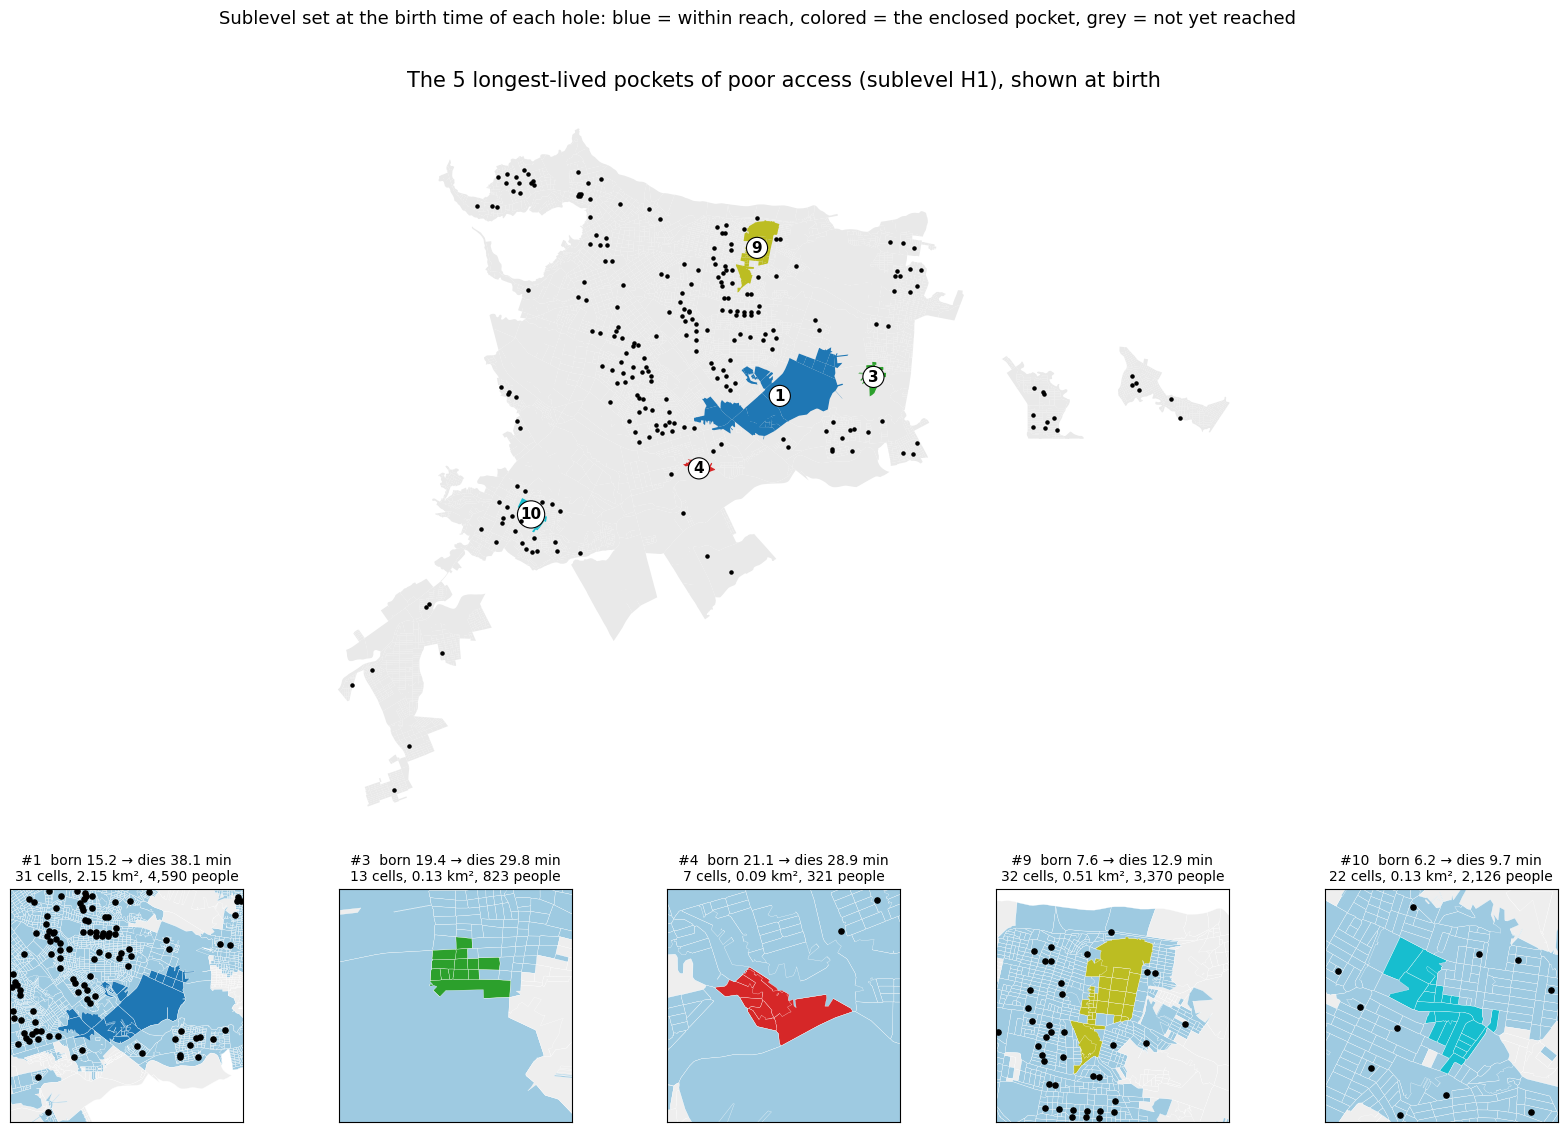

,birth_min,death_min,lifetime_min,n_cells,area_km2,population,centroid_x,centroid_y,match,pockets_equal_beta1
rank,,,,,,,,,,
1,15.156202,38.097222,22.941020,31,2.154044,4590.0,654581.906777,456002.933686,exact,False
3,19.425914,29.810552,10.384638,13,0.128936,823.0,656334.384048,456358.524690,exact,False
4,21.083125,28.926238,7.843113,7,0.094661,321.0,653067.793446,454646.732728,exact,False
9,7.594897,12.851531,5.256633,32,0.511123,3370.0,654155.288616,458774.445936,exact,False
10,6.238051,9.718642,3.480591,22,0.133021,2126.0,649925.588646,453784.278288,exact,False


In [87]:
import numpy as np
import pandas as pd
import shapely
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import to_hex
from shapely.geometry import box
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

# ------------------------------------------------------------------
# Parameters
# ------------------------------------------------------------------
N_HOLES = 10
DIAGRAM = sublevel_diagrams[1]    # sublevel H1: pockets of poor access ringed by better access
VALUES = f_sub                    # the function the sublevel diagram was built from

ADJ_TOL_M = 0.5          # same tolerance used for the filtration adjacency
MIN_CONTACT_M = 2.0      # shared-border length for two uncovered cells to count as connected
BOUNDARY_TOL_M = 1.0     # cells this close to the city limit touch the "outside"
VALUE_TOL = 1e-9
ZOOM_PAD_FRAC = 0.35
ZOOM_MIN_HALF_WIDTH_M = 300
SHOW_HOSPITALS = True

# ------------------------------------------------------------------
# 1. The N longest-lived finite H1 classes
# ------------------------------------------------------------------
finite_class = np.isfinite(DIAGRAM[:, 1])
lifetime = np.where(finite_class, DIAGRAM[:, 1] - DIAGRAM[:, 0], -np.inf)
top = np.argsort(lifetime)[::-1][:N_HOLES]
print(f"H1 classes: {len(DIAGRAM):,} total, {(~finite_class).sum()} essential (skipped)")

# ------------------------------------------------------------------
# 2. Geometry: contact graph for the *uncovered* cells.
# A hole is a pocket of cells with value > t, and those cells connect
# through shared borders only (rook contact), not through corners.
# ------------------------------------------------------------------
cells = block_tessellation[valid]
geoms = cells.geometry.to_numpy()
buffered = shapely.buffer(geoms, ADJ_TOL_M / 2, quad_segs=2)
contact_m = shapely.area(shapely.intersection(buffered[edge_i], buffered[edge_j])) / ADJ_TOL_M
rook = contact_m >= MIN_CONTACT_M
rook_i, rook_j = edge_i[rook], edge_j[rook]

# Cells touching the city limit are connected to the outside world
city_geom = city_limit.union_all() if hasattr(city_limit, "union_all") else city_limit
touch_full = np.zeros(len(block_tessellation), dtype=bool)
touch_full[block_tessellation.sindex.query(
    city_geom.boundary, predicate="dwithin", distance=BOUNDARY_TOL_M)] = True
touches_limit = touch_full[valid]

def uncovered_components(t):
    """Components of {cells with value > t}, plus per-component statistics."""
    inactive = VALUES > t
    keep = inactive[rook_i] & inactive[rook_j]
    graph = coo_matrix(
        (np.ones(keep.sum()), (rook_i[keep], rook_j[keep])),
        shape=(n_cells, n_cells),
    )
    _, labels = connected_components(graph, directed=False)
    n_labels = labels.max() + 1
    lab = labels[inactive]
    size = np.bincount(lab, minlength=n_labels)
    reaches_outside = np.bincount(lab, weights=touches_limit[inactive], minlength=n_labels) > 0
    max_value = np.full(n_labels, -np.inf)
    np.maximum.at(max_value, lab, VALUES[inactive])
    return inactive, labels, size, reaches_outside, max_value

# ------------------------------------------------------------------
# 3. Locate each class on the map.
# At its birth time t_b a new enclosed pocket appears. It is the
# uncovered component that (a) is not connected to the outside,
# (b) touches a cell that entered exactly at t_b (the cell that closed
# the ring) and (c) is finally filled at the class's death time.
# ------------------------------------------------------------------
area_m2 = shapely.area(geoms)
has_population = "poblacion" in cells.columns
population = (
    cells["poblacion"].fillna(0).to_numpy(dtype=float) if has_population else None
)

records, hole_masks, taken = [], {}, set()
for rank, k in enumerate(top, start=1):
    birth, death = DIAGRAM[k]
    inactive, labels, size, outside, max_value = uncovered_components(birth)

    closing = np.isclose(VALUES, birth, rtol=0, atol=VALUE_TOL)
    next_to_closing = np.unique(np.concatenate([
        labels[rook_j[closing[rook_i] & inactive[rook_j]]],
        labels[rook_i[closing[rook_j] & inactive[rook_i]]],
    ]))
    enclosed = (~outside) & (size > 0)
    betti_1 = int(((DIAGRAM[:, 0] <= birth) & (DIAGRAM[:, 1] > birth)).sum())
    dies_here = np.isclose(max_value, death, rtol=0, atol=VALUE_TOL)

    strict = np.flatnonzero(enclosed & dies_here & np.isin(np.arange(len(size)), next_to_closing))
    relaxed = np.flatnonzero(enclosed & dies_here)
    candidates, how = (strict, "exact") if len(strict) else (relaxed, "relaxed")

    chosen = None
    for label in candidates[np.argsort(-size[candidates])]:
        members = np.flatnonzero(labels == label)
        signature = (round(float(birth), 9), int(members.min()))
        if signature not in taken:
            taken.add(signature)
            chosen = members
            break

    if chosen is None:
        print(f"#{rank}: no enclosed pocket found for birth={birth:.2f}, death={death:.2f}")
        continue

    mask = np.zeros(n_cells, dtype=bool)
    mask[chosen] = True
    hole_masks[rank] = mask
    centroid = shapely.centroid(shapely.union_all(geoms[chosen]))
    records.append({
        "rank": rank,
        "birth_min": birth,
        "death_min": death,
        "lifetime_min": death - birth,
        "n_cells": len(chosen),
        "area_km2": area_m2[chosen].sum() / 1e6,
        "population": population[chosen].sum() if has_population else np.nan,
        "centroid_x": centroid.x,
        "centroid_y": centroid.y,
        "match": how if len(candidates) == 1 else f"{how} ({len(candidates)} tied)",
        "pockets_equal_beta1": int(enclosed.sum()) == betti_1,
    })

holes_table = pd.DataFrame(records).set_index("rank")
print(holes_table.round(2).to_string())

# ------------------------------------------------------------------
# 4. Plot: overview map + one zoom per hole, drawn at its birth time
# ------------------------------------------------------------------
palette = plt.get_cmap("tab10")
ranks = list(holes_table.index)
fig = plt.figure(figsize=(21, 17))
grid = gridspec.GridSpec(3, 5, height_ratios=[3.2, 1, 1], hspace=0.12, wspace=0.05)

ax_map = fig.add_subplot(grid[0, :])
cells.plot(ax=ax_map, color="#e9e9e9", linewidth=0)
for rank in ranks:
    cells[hole_masks[rank]].plot(ax=ax_map, color=palette((rank - 1) % 10), linewidth=0)
    row = holes_table.loc[rank]
    ax_map.annotate(
        str(rank), (row.centroid_x, row.centroid_y), ha="center", va="center",
        fontsize=11, fontweight="bold",
        bbox=dict(boxstyle="circle,pad=0.2", fc="white", ec="black", lw=0.8),
    )
if SHOW_HOSPITALS:
    health_centers.plot(ax=ax_map, color="black", markersize=5, zorder=3)
ax_map.set_title(
    f"The {len(ranks)} longest-lived pockets of poor access (sublevel H1), shown at birth", fontsize=15)
ax_map.set_aspect("equal")
ax_map.set_axis_off()

for slot, rank in enumerate(ranks):
    ax = fig.add_subplot(grid[1 + slot // 5, slot % 5])
    row = holes_table.loc[rank]
    mask = hole_masks[rank]
    x0, y0, x1, y1 = shapely.total_bounds(geoms[mask])
    half = max(max(x1 - x0, y1 - y0) / 2 * (1 + 2 * ZOOM_PAD_FRAC), ZOOM_MIN_HALF_WIDTH_M)
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    window = box(cx - half, cy - half, cx + half, cy + half)
    local = np.sort(cells.sindex.query(window, predicate="intersects"))

    colors = np.where(VALUES[local] <= row.birth_min, "#9ecae1", "#eeeeee").astype(object)
    colors[mask[local]] = to_hex(palette((rank - 1) % 10))
    cells.iloc[local].plot(ax=ax, color=list(colors), edgecolor="white", linewidth=0.2)
    if SHOW_HOSPITALS:
        nearby_hospitals = health_centers.cx[cx - half:cx + half, cy - half:cy + half]
        if len(nearby_hospitals):
            nearby_hospitals.plot(ax=ax, color="black", markersize=14, zorder=3)
    ax.set_xlim(cx - half, cx + half)
    ax.set_ylim(cy - half, cy + half)
    ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlabel(""); ax.set_ylabel("")
    pop_text = f", {row.population:,.0f} people" if has_population else ""
    ax.set_title(
        f"#{rank}  born {row.birth_min:.1f} → dies {row.death_min:.1f} min\n"
        f"{int(row.n_cells)} cells, {row.area_km2:.2f} km²{pop_text}",
        fontsize=10,
    )

fig.suptitle("Sublevel set at the birth time of each hole: blue = within reach, "
             "colored = the enclosed pocket, grey = not yet reached", fontsize=13, y=0.93)
fig.savefig(output_dir / "08_longest_lived_holes.png", dpi=300, bbox_inches="tight")
plt.show()
holes_table

T = 15 min: 5 classes alive (1 essential); showing the top 5 by persistence
Graph ready in 2.8s: 15,728 contact edges, 0 footprint gaps vs 1 essential classes
Graph check at T: 3 enclosed pockets vs 5 alive classes (MISMATCH: some pockets leak or are spurious)
#1: born 7.41, dies 60.00 -> no enclosed pocket at T (essential) [0.0s]
#2: born 8.27, dies 20.92 -> no enclosed pocket at T (finite) [0.0s]
#3: born 11.83, dies 18.24 -> no enclosed pocket at T (finite) [0.0s]
      essential  birth_min  death_min  persistence_min  remaining_min  n_cells  area_km2  population  centroid_x  centroid_y  match  consistent
rank                                                                                                                                           
4         False      14.40      15.60              1.2           0.60        1       0.0        55.0   653855.99   454715.00  exact        True
5         False      14.63      15.03              0.4           0.03        1       0.0       1

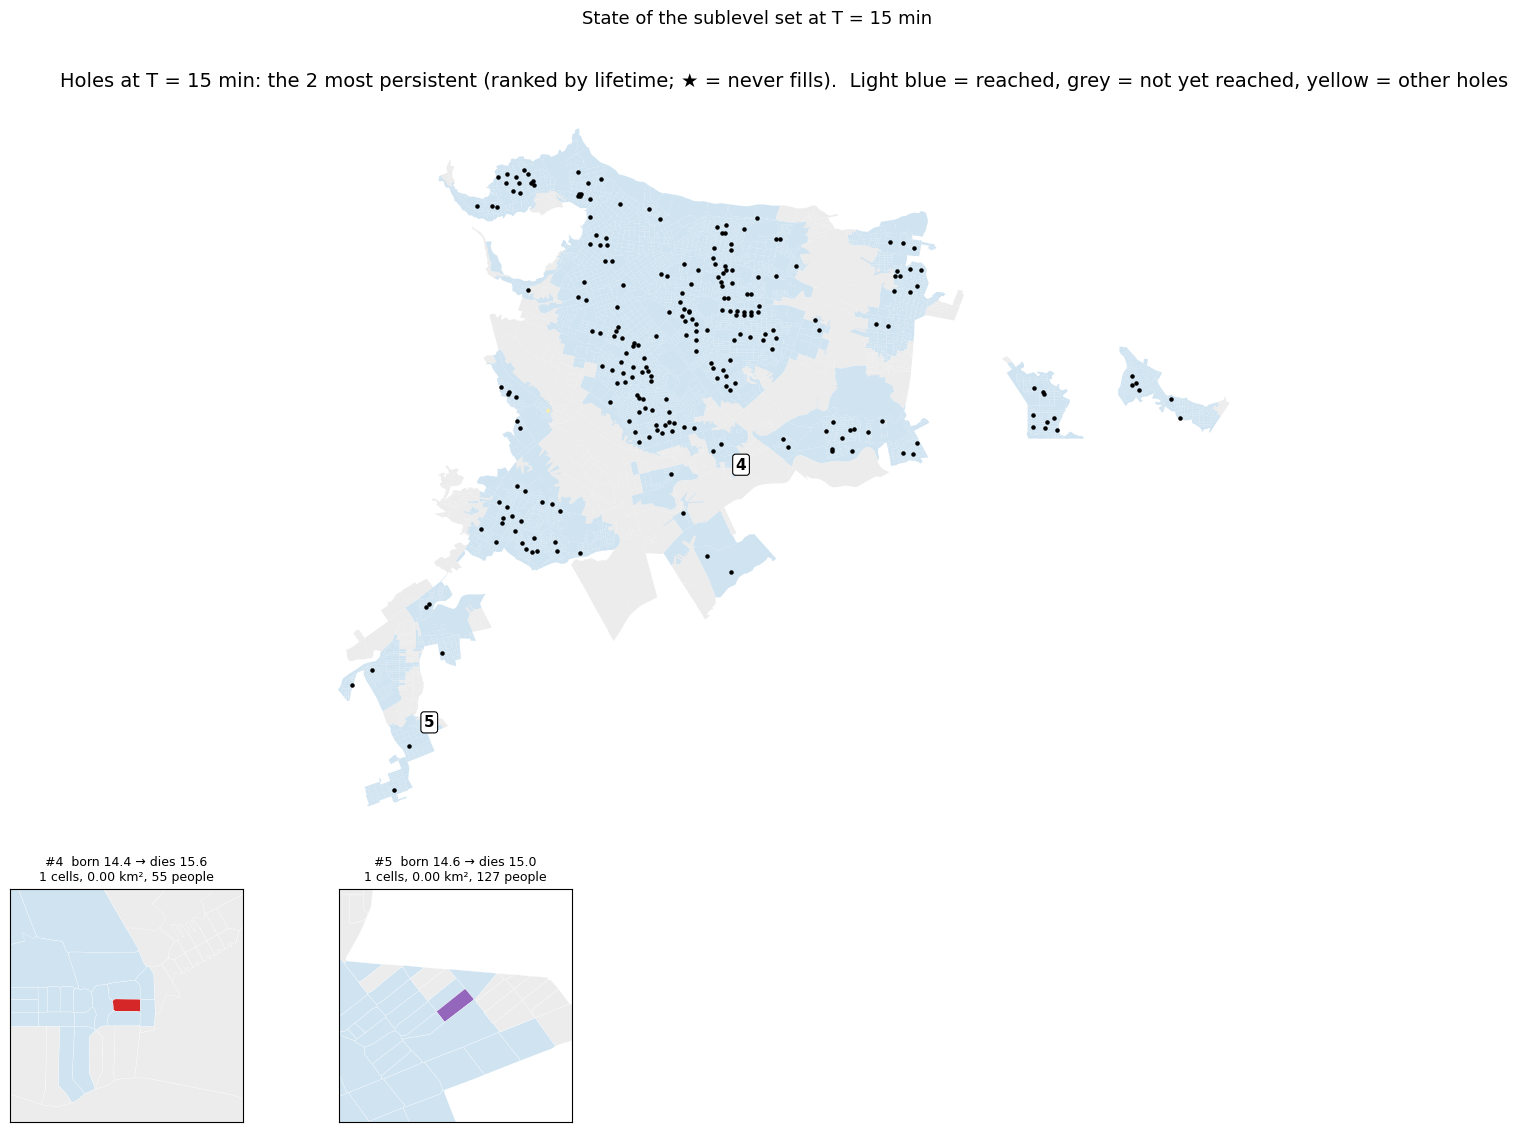

,essential,birth_min,death_min,persistence_min,remaining_min,n_cells,area_km2,population,centroid_x,centroid_y,match,consistent
rank,,,,,,,,,,,,
4,False,14.396088,15.600135,1.204047,0.600135,1,0.002177,55.0,653855.989540,454715.000977,exact,True
5,False,14.625422,15.025186,0.399764,0.025186,1,0.003380,127.0,648019.679322,449891.918636,exact,True


In [88]:
import time
import numpy as np
import pandas as pd
import shapely
import geopandas as gpd
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from matplotlib.colors import to_hex
from shapely.geometry import box, Polygon
from scipy.sparse import coo_matrix
from scipy.sparse.csgraph import connected_components

# ------------------------------------------------------------------
# Parameters
# ------------------------------------------------------------------
QUERY_T = 15.0                    # time (minutes) at which the holes are drawn
N_HOLES = 10
RANK_BY = "persistence"           # "persistence" = death - birth  |  "remaining" = death - QUERY_T
INCLUDE_ESSENTIAL = True          # essential classes get death = END_VALUE
SHOW_OTHER_HOLES = True           # tint the holes that are not in the top N
VALUES = f_sub                    # the function the sublevel diagram was built from
END_VALUE = float(T_END) if T_END is not None else float(VALUES.max())

ADJ_TOL_M = 0.5            # same tolerance used for the filtration adjacency
MIN_CONTACT_M = 5.0        # shared-border length for two uncovered cells to count as connected
BOUNDARY_TOL_M = 1.0       # cells this close to the city limit touch it
MIN_ENCLAVE_AREA_M2 = 50.0 # ignore footprint gaps smaller than this (slivers)
VALUE_TOL = 1e-9
BIRTH_EPS = 1e-6
ZOOM_PAD_FRAC = 0.35
ZOOM_MIN_HALF_WIDTH_M = 300
SHOW_HOSPITALS = True

# ------------------------------------------------------------------
# 1. Classes alive at QUERY_T, ranked
# ------------------------------------------------------------------
DIAGRAM = sublevel_diagrams[1].copy()
essential_class = ~np.isfinite(DIAGRAM[:, 1])
if INCLUDE_ESSENTIAL:
    DIAGRAM[essential_class, 1] = END_VALUE
alive = (DIAGRAM[:, 0] <= QUERY_T + VALUE_TOL) & (DIAGRAM[:, 1] > QUERY_T + VALUE_TOL)
if not INCLUDE_ESSENTIAL:
    alive &= ~essential_class
persistence = DIAGRAM[:, 1] - DIAGRAM[:, 0]
score = persistence if RANK_BY == "persistence" else DIAGRAM[:, 1] - QUERY_T
alive_idx = np.flatnonzero(alive)
top = alive_idx[np.argsort(-score[alive_idx])][:N_HOLES]
print(f"T = {QUERY_T:g} min: {alive.sum()} classes alive "
      f"({(alive & essential_class).sum()} essential); showing the top {len(top)} by {RANK_BY}")
if QUERY_T >= END_VALUE:
    print("WARNING: QUERY_T is at or beyond END_VALUE, where every pocket has been filled.")

# ------------------------------------------------------------------
# 2. Graph of the *uncovered* cells (shared borders only), plus one node per
#    footprint gap (enclave) and one for "outside".
# ------------------------------------------------------------------
t0 = time.time()
cells = block_tessellation[valid]
geoms = cells.geometry.to_numpy()
area_m2 = shapely.area(geoms)
tree = cells.sindex

buffered = shapely.buffer(geoms, ADJ_TOL_M / 2, quad_segs=2)
contact_m = shapely.area(shapely.intersection(buffered[edge_i], buffered[edge_j])) / ADJ_TOL_M
rook = contact_m >= MIN_CONTACT_M
rook_i, rook_j = edge_i[rook], edge_j[rook]

city_geom = city_limit.union_all() if hasattr(city_limit, "union_all") else city_limit
parts = list(shapely.get_parts(city_geom))
enclave_polys = [Polygon(r) for p in parts for r in p.interiors]
enclave_polys = [e for e in enclave_polys if e.area >= MIN_ENCLAVE_AREA_M2]
n_enc = len(enclave_polys)
OUT_NODE = n_cells + n_enc
n_nodes = n_cells + n_enc + 1

border_cell, border_node = [], []
for j, e in enumerate(enclave_polys):
    near = tree.query(e.exterior, predicate="dwithin", distance=BOUNDARY_TOL_M)
    border_cell.append(near); border_node.append(np.full(len(near), n_cells + j))
for p in parts:
    near = tree.query(p.exterior, predicate="dwithin", distance=BOUNDARY_TOL_M)
    border_cell.append(near); border_node.append(np.full(len(near), OUT_NODE))
border_cell = np.concatenate(border_cell).astype(int)
border_node = np.concatenate(border_node).astype(int)
print(f"Graph ready in {time.time() - t0:.1f}s: {len(rook_i):,} contact edges, "
      f"{n_enc} footprint gaps vs {essential_class.sum()} essential classes")

def uncovered_components(reached_up_to):
    inactive = VALUES > reached_up_to
    keep = inactive[rook_i] & inactive[rook_j]
    bkeep = inactive[border_cell]
    src = np.concatenate([rook_i[keep], border_cell[bkeep]])
    dst = np.concatenate([rook_j[keep], border_node[bkeep]])
    graph = coo_matrix((np.ones(len(src)), (src, dst)), shape=(n_nodes, n_nodes))
    _, labels = connected_components(graph, directed=False)
    n_labels = labels.max() + 1
    lab = labels[:n_cells][inactive]
    size = np.bincount(lab, minlength=n_labels)
    max_value = np.full(n_labels, -np.inf)
    np.maximum.at(max_value, lab, VALUES[inactive])
    has_border = np.zeros(n_labels, dtype=bool)
    has_border[labels[n_cells:]] = True
    return inactive, labels, size, has_border, max_value

def labels_next_to_closing(birth, inactive, labels):
    closing = np.isclose(VALUES, birth, rtol=0, atol=VALUE_TOL)
    return np.unique(np.concatenate([
        labels[rook_j[closing[rook_i] & inactive[rook_j]]],
        labels[rook_i[closing[rook_j] & inactive[rook_i]]],
        labels[border_node[closing[border_cell]]],
    ]))

def border_groups(labels):
    groups = {}
    for node in range(n_cells, n_nodes):
        groups.setdefault(labels[node], []).append(node)
    return {node: tuple(groups[labels[node]]) for node in range(n_cells, n_nodes)}

enc_nodes = n_cells + np.arange(n_enc)

# ------------------------------------------------------------------
# 3. Where was the class's pocket when it was born? (needed for essential
#    classes, which have no "last cell", and to break ties between classes
#    that die at the same value, e.g. on the clipped plateau)
# ------------------------------------------------------------------
claimed_enclaves, taken = set(), set()

def birth_pocket(birth, death, is_essential):
    inactive, labels, size, has_border, max_value = uncovered_components(birth)
    next_to_closing = labels_next_to_closing(birth, inactive, labels)
    bounded = labels[enc_nodes] != labels[OUT_NODE] if n_enc else np.zeros(0, dtype=bool)
    finite_pockets = (~has_border) & (size > 0)
    how = "exact"
    if is_essential:
        _, labels_prev, *_ = uncovered_components(birth - BIRTH_EPS)
        sig, sig_prev = border_groups(labels), border_groups(labels_prev)
        newly = [j for j in range(n_enc) if bounded[j] and sig[n_cells + j] != sig_prev[n_cells + j]]
        candidates = np.unique(labels[enc_nodes[newly]]) if newly else np.array([], dtype=int)
        if not len(candidates) and n_enc:
            free_gaps = [j for j in range(n_enc) if bounded[j] and j not in claimed_enclaves]
            candidates = np.unique(labels[enc_nodes[free_gaps]]) if free_gaps else candidates
            how = "relaxed"
    else:
        dies_here = np.isclose(max_value, death, rtol=0, atol=VALUE_TOL)
        candidates = np.flatnonzero(finite_pockets & dies_here)
    if len(candidates) and np.isin(candidates, next_to_closing).any():
        candidates = candidates[np.isin(candidates, next_to_closing)]
    elif len(candidates):
        how = "relaxed"
    for label in candidates[np.argsort(-size[candidates])] if len(candidates) else []:
        members = np.flatnonzero(inactive & (labels[:n_cells] == label))
        enclave_ids = [j for j in range(n_enc) if labels[n_cells + j] == label]
        signature = (round(float(birth), 9), int(members.min()) if len(members) else -int(label))
        if signature in taken:
            continue
        if is_essential and how == "relaxed" and set(enclave_ids) <= claimed_enclaves:
            continue
        taken.add(signature)
        claimed_enclaves.update(enclave_ids)
        return members, enclave_ids
    return None

# ------------------------------------------------------------------
# 4. The holes at QUERY_T, and which class each one belongs to.
# Each pocket at T is filled when its highest cell enters, and that value
# is the death time of the (oldest) class living in it. Essential classes
# are followed from their birth pocket to the gap they surround.
# ------------------------------------------------------------------
inactive, labels, size, has_border, max_value = uncovered_components(QUERY_T + VALUE_TOL)
finite_pockets = (~has_border) & (size > 0)
bounded_enc = labels[enc_nodes] != labels[OUT_NODE] if n_enc else np.zeros(0, dtype=bool)
n_graph_pockets = int(finite_pockets.sum()) + len(np.unique(labels[enc_nodes[bounded_enc]]))
print(f"Graph check at T: {n_graph_pockets} enclosed pockets vs {alive.sum()} alive classes "
      f"({'consistent' if n_graph_pockets == alive.sum() else 'MISMATCH: some pockets leak or are spurious'})")

has_population = "poblacion" in cells.columns
population = cells["poblacion"].fillna(0).to_numpy(dtype=float) if has_population else None

# Essential classes: place every alive one (there are only a few). A single class
# that cannot be traced back to its birth is assigned to the one enclosed gap left over.
essential_label, by_elimination = {}, set()
alive_essential = sorted(np.flatnonzero(alive & essential_class), key=lambda k: DIAGRAM[k, 0])
for k in alive_essential:
    found = birth_pocket(DIAGRAM[k, 0], DIAGRAM[k, 1], True)
    if found is None:
        continue
    for j in found[1]:
        cand = labels[n_cells + j]
        if bounded_enc[j] and cand not in essential_label.values():
            essential_label[k] = cand
            break
unlocated = [k for k in alive_essential if k not in essential_label]
unclaimed = (set(np.unique(labels[enc_nodes[bounded_enc]])) if n_enc else set()) - set(essential_label.values())
if len(unlocated) == 1 and len(unclaimed) == 1:
    essential_label[unlocated[0]] = next(iter(unclaimed))
    by_elimination.add(unlocated[0])

records, hole_label, hole_enclaves, used_labels = [], {}, {}, set()
for rank, k in enumerate(top, start=1):
    t_class = time.time()
    birth, death = DIAGRAM[k]
    is_essential = bool(essential_class[k])
    label, how, n_tied, enclave_ids = None, "exact", 1, []

    if is_essential:
        label = essential_label.get(k)
        if k in by_elimination:
            how = "by elimination"
    else:
        cands = [c for c in np.flatnonzero(finite_pockets & np.isclose(max_value, death, rtol=0, atol=VALUE_TOL))
                 if c not in used_labels]
        if len(cands) == 1:
            label = cands[0]
        elif len(cands) > 1:                      # tie: follow the birth pocket forward
            found = birth_pocket(birth, death, False)
            if found is not None:
                overlap = [(labels[found[0]] == c).sum() for c in cands]
                label = cands[int(np.argmax(overlap))] if max(overlap) > 0 else None
            if label is None:
                label = max(cands, key=lambda c: size[c])
                how = "relaxed"
            n_tied = len(cands)

    if label is None:
        print(f"#{rank}: born {birth:.2f}, dies {death:.2f} -> no enclosed pocket at T "
              f"({'essential' if is_essential else 'finite'}) [{time.time() - t_class:.1f}s]")
        continue

    used_labels.add(label)
    members = np.flatnonzero(inactive & (labels[:n_cells] == label))
    enclave_ids = [j for j in range(n_enc) if labels[n_cells + j] == label]
    hole_label[rank] = label
    hole_enclaves[rank] = [enclave_polys[j] for j in enclave_ids]
    pieces = np.concatenate([geoms[members], np.array(hole_enclaves[rank], dtype=object)])
    weights = shapely.area(pieces)
    centres = shapely.centroid(pieces)
    records.append({
        "rank": rank,
        "essential": is_essential,
        "birth_min": birth,
        "death_min": death,
        "persistence_min": death - birth,
        "remaining_min": death - QUERY_T,
        "n_cells": len(members),
        "area_km2": (area_m2[members].sum() + sum(e.area for e in hole_enclaves[rank])) / 1e6,
        "population": population[members].sum() if has_population else np.nan,
        "centroid_x": np.average(shapely.get_x(centres), weights=weights),
        "centroid_y": np.average(shapely.get_y(centres), weights=weights),
        "match": how if n_tied == 1 else f"{how} ({n_tied} tied)",
        "consistent": True if is_essential else bool(np.isclose(max_value[label], death, rtol=0, atol=1e-6)),
    })

holes_table = pd.DataFrame(records).set_index("rank")
print(holes_table.round(2).to_string())

# ------------------------------------------------------------------
# 5. Plot the state of the city at QUERY_T
# ------------------------------------------------------------------
palette = plt.get_cmap("tab10")
ranks = list(holes_table.index)
REACHED, UNREACHED, OTHER_HOLE = "#cfe3f1", "#ececec", "#f6eaa6"

colors = np.where(VALUES <= QUERY_T + VALUE_TOL, REACHED, UNREACHED).astype(object)
if SHOW_OTHER_HOLES:
    colors[inactive & (finite_pockets[labels[:n_cells]] | np.isin(labels[:n_cells], labels[enc_nodes[bounded_enc]]))] = OTHER_HOLE
for rank in ranks:
    colors[inactive & (labels[:n_cells] == hole_label[rank])] = to_hex(palette((rank - 1) % 10))

fig = plt.figure(figsize=(21, 17))
grid = gridspec.GridSpec(3, 5, height_ratios=[3.2, 1, 1], hspace=0.12, wspace=0.05)

def draw_enclaves(ax, rank, alpha=1.0):
    if hole_enclaves[rank]:
        gpd.GeoSeries(hole_enclaves[rank], crs=cells.crs).plot(
            ax=ax, color=to_hex(palette((rank - 1) % 10)), alpha=alpha, edgecolor="black", linewidth=1.2)

ax_map = fig.add_subplot(grid[0, :])
cells.plot(ax=ax_map, color=list(colors), linewidth=0)
for rank in ranks:
    draw_enclaves(ax_map, rank)
    row = holes_table.loc[rank]
    ax_map.annotate(
        ("★" if row.essential else "") + str(rank), (row.centroid_x, row.centroid_y),
        ha="center", va="center", fontsize=11, fontweight="bold",
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="black", lw=0.8),
    )
if SHOW_HOSPITALS:
    health_centers.plot(ax=ax_map, color="black", markersize=5, zorder=3)
ax_map.set_title(
    f"Holes at T = {QUERY_T:g} min: the {len(ranks)} most persistent "
    f"(ranked by {'lifetime' if RANK_BY == 'persistence' else 'time left'}; ★ = never fills).  "
    "Light blue = reached, grey = not yet reached"
    + (", yellow = other holes" if SHOW_OTHER_HOLES else ""), fontsize=14)
ax_map.set_aspect("equal")
ax_map.set_axis_off()

for slot, rank in enumerate(ranks):
    ax = fig.add_subplot(grid[1 + slot // 5, slot % 5])
    row = holes_table.loc[rank]
    mask = inactive & (labels[:n_cells] == hole_label[rank])
    pieces = np.concatenate([geoms[mask], np.array(hole_enclaves[rank], dtype=object)])
    x0, y0, x1, y1 = shapely.total_bounds(pieces)
    half = max(max(x1 - x0, y1 - y0) / 2 * (1 + 2 * ZOOM_PAD_FRAC), ZOOM_MIN_HALF_WIDTH_M)
    cx, cy = (x0 + x1) / 2, (y0 + y1) / 2
    local = np.sort(cells.sindex.query(box(cx - half, cy - half, cx + half, cy + half), predicate="intersects"))
    cells.iloc[local].plot(ax=ax, color=list(colors[local]), edgecolor="white", linewidth=0.2)
    draw_enclaves(ax, rank, alpha=0.9)
    if SHOW_HOSPITALS:
        nearby = health_centers.cx[cx - half:cx + half, cy - half:cy + half]
        if len(nearby):
            nearby.plot(ax=ax, color="black", markersize=14, zorder=3)
    ax.set_xlim(cx - half, cx + half); ax.set_ylim(cy - half, cy + half)
    ax.set_aspect("equal"); ax.set_xticks([]); ax.set_yticks([])
    ax.set_xlabel(""); ax.set_ylabel("")
    pop_text = f", {row.population:,.0f} people" if has_population else ""
    fate = (f"never fills (={row.death_min:.0f})" if row.essential else f"dies {row.death_min:.1f}")
    ax.set_title(
        f"{'★ ' if row.essential else ''}#{rank}  born {row.birth_min:.1f} → {fate}\n"
        f"{int(row.n_cells)} cells, {row.area_km2:.2f} km²{pop_text}", fontsize=9)

fig.suptitle(f"State of the sublevel set at T = {QUERY_T:g} min", fontsize=13, y=0.93)
fig.savefig(
    output_dir / f"09_sublevel_holes_at_{QUERY_T:g}_min.png",
    dpi=300,
    bbox_inches="tight",
)
plt.show()
holes_table